# Lab 4: Ecology Models and Snow Leopard Tracking in Python
**Course:** Environmental Science for Sustainable Development  
**Source:** Ecology Lab, S. Hsiang  
**Format:** Python Jupyter notebook

This notebook follows the assignment in order. Sections 1, 2, and 3 contain Python code. Written answers and interpretations will be added after the coding sections.

## Setup and submission checklist
- Write the scripts yourself in Python and include the code in the submission.
- Read each simulation section before implementing it. Plan inputs, outputs, array dimensions, indexing, and information flow; include the requested planning diagrams.
- For each simulation, include its plan, code, plots, and written interpretation. Title plots and label axes.
- State any chosen initial values and modeling assumptions. Complete the remaining empty code cells section by section.

# 1. Solving difficult equations
## 1.1 Plot the two surfaces
Create a two-dimensional grid from -5 to 5 in both x and y, spaced by 0.1. Plot the population surface z = x² + sin(y) + xy. On the same axes, plot the conservation surface z = x + y. Describe their shapes and where they appear to meet.

**Python implementation:** grid construction and surface plots.

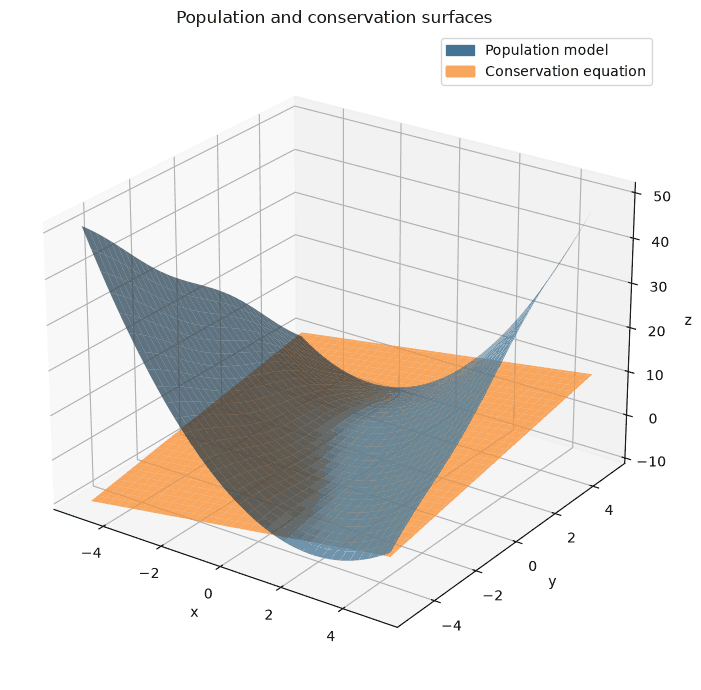

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

x_values = np.arange(-5.0, 5.0 + 0.05, 0.1)
y_values = np.arange(-5.0, 5.0 + 0.05, 0.1)
X, Y = np.meshgrid(x_values, y_values)

z_population = X**2 + np.sin(Y) + X * Y
z_conservation = X + Y

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, z_population, color="tab:blue", alpha=0.65,
                rstride=3, cstride=3)
ax.plot_surface(X, Y, z_conservation, color="tab:orange", alpha=0.65,
                rstride=3, cstride=3)
ax.set(xlabel="x", ylabel="y", zlabel="z",
       title="Population and conservation surfaces")
ax.legend(handles=[Patch(color="tab:blue", label="Population model"),
                   Patch(color="tab:orange", label="Conservation equation")])
ax.view_init(elev=25, azim=-55)
plt.tight_layout()
plt.show()

## 1.2 Find and interpret the intersection
Plot the intersection of the surfaces. At x = 1, how many y values satisfy both equations? What is z at each solution? Explain how the plot and numerical estimates support the answer.

**Python implementation:** intersection plot and x = 1 calculations.

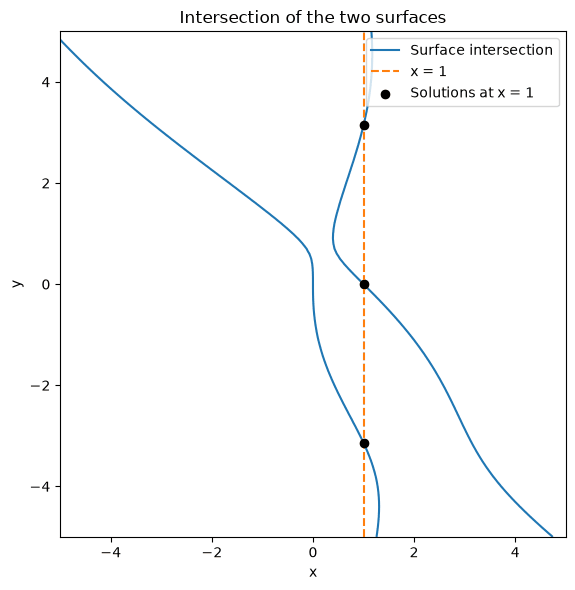

Number of solutions at x = 1: 3
y = -3.141593, z = -2.141593
y = 0.000000, z = 1.000000
y = 3.141593, z = 4.141593


In [2]:
from scipy.optimize import brentq

# The zero contour of this difference is the intersection in the x-y plane.
difference = z_population - z_conservation
x_fixed = 1.0

def difference_at_fixed_x(y):
    return x_fixed**2 + np.sin(y) + x_fixed * y - (x_fixed + y)

y_scan = np.linspace(-5.0, 5.0, 2001)
sample_values = difference_at_fixed_x(y_scan)
roots = []
for i in range(len(y_scan) - 1):
    if np.isclose(sample_values[i], 0.0, atol=1e-12):
        roots.append(y_scan[i])
    elif sample_values[i] * sample_values[i + 1] < 0:
        roots.append(brentq(difference_at_fixed_x, y_scan[i], y_scan[i + 1]))
if np.isclose(sample_values[-1], 0.0, atol=1e-12):
    roots.append(y_scan[-1])

y_roots = np.array(sorted(set(np.round(roots, 10))))
z_roots = x_fixed + y_roots

fig, ax = plt.subplots(figsize=(8, 6))
ax.contour(X, Y, difference, levels=[0], colors="tab:blue")
ax.plot([], [], color="tab:blue", label="Surface intersection")
ax.axvline(x_fixed, color="tab:orange", linestyle="--", label="x = 1")
ax.scatter(np.full_like(y_roots, x_fixed), y_roots, color="black",
           zorder=3, label="Solutions at x = 1")
ax.set(xlabel="x", ylabel="y", xlim=(-5, 5), ylim=(-5, 5),
       title="Intersection of the two surfaces")
ax.set_aspect("equal")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Number of solutions at x = {x_fixed:g}: {len(y_roots)}")
for y_value, z_value in zip(y_roots, z_roots):
    print(f"y = {y_value:.6f}, z = {z_value:.6f}")

# 2. Koala population models
## 2.1 Unrestricted growth: assumptions and plan
Given one-third mature males, one-third mature females, one-third juveniles, and a one-half annual birth probability per mature female, what is the growth parameter r in N(t+1) = N(t) + rN(t)? What extra information is needed to find population at a specified time? Choose and report an initial population μ.

Before coding, draw the input and output arrays, their dimensions and indices, and the yearly calculation flow. Attach or reproduce the plan here.

**Heuristic array and computation plan (Python indices):**

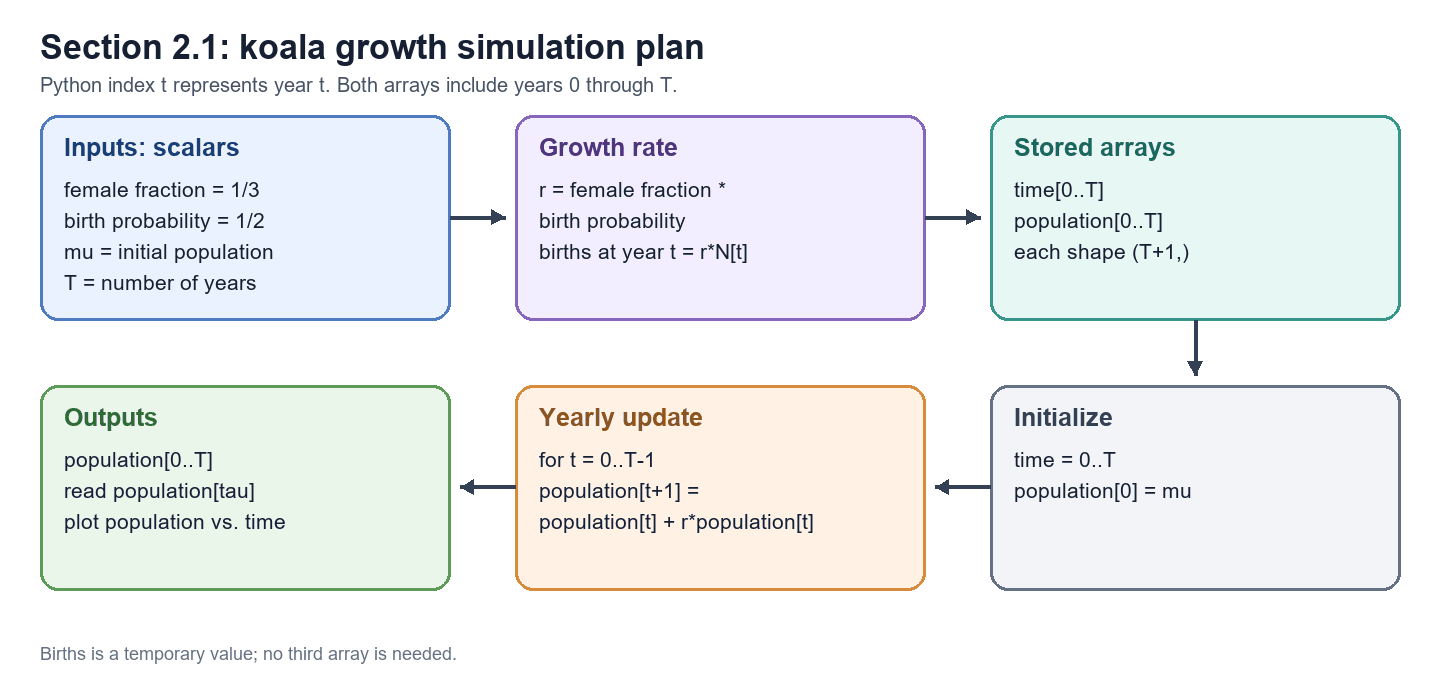

The stored time and population arrays each have shape (T+1,). Expected births are a temporary value in each yearly update. The initial population and numerical response can be filled in when Section 2 is solved.

## 2.2 Simulate unrestricted growth
Use one-year time steps to compute population over time from μ. Plot population against time and describe its behavior. Include the script and the plot.

**Python implementation:** growth simulation and plot.

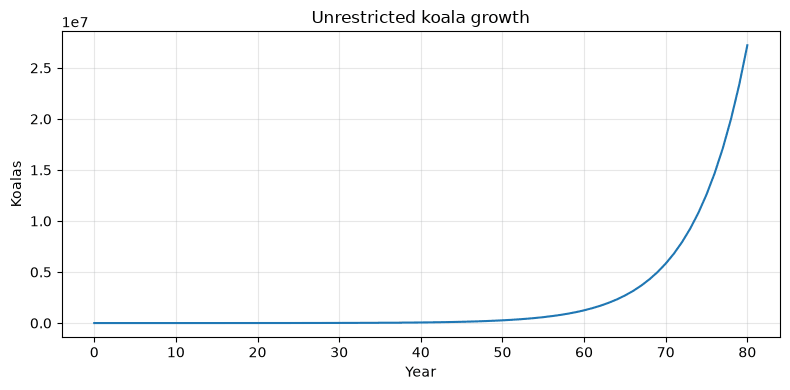

r = 0.166667; N0 = 120


In [3]:
female_fraction = 1 / 3
birth_probability = 1 / 2
r_koala = female_fraction * birth_probability
mu = 120.0  # Chosen initial population
years = 80
time = np.arange(years + 1)
population = np.empty(years + 1, dtype=float)
population[0] = mu
for t in range(years):
    expected_births = r_koala * population[t]
    population[t + 1] = population[t] + expected_births
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(time, population)
ax.set(xlabel="Year", ylabel="Koalas", title="Unrestricted koala growth")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"r = {r_koala:.6f}; N0 = {mu:g}")


## 2.3 Carrying capacity: algebra and plan
A fixed forest has 5,000 eucalyptus trees; each koala needs five trees. Determine koala carrying capacity K. For the discrete logistic update N(t+1) = N(t) + rN(t)[1 − N(t)/K], check algebraically the stated growth or decline when N is below or above K, and the small-population limit.

Plan the arrays and update order before coding. Attach or reproduce the requested plan.

**Heuristic array and computation plan (Python indices):** the same script is reused for koalas (2.4) and beetles alone (2.5).

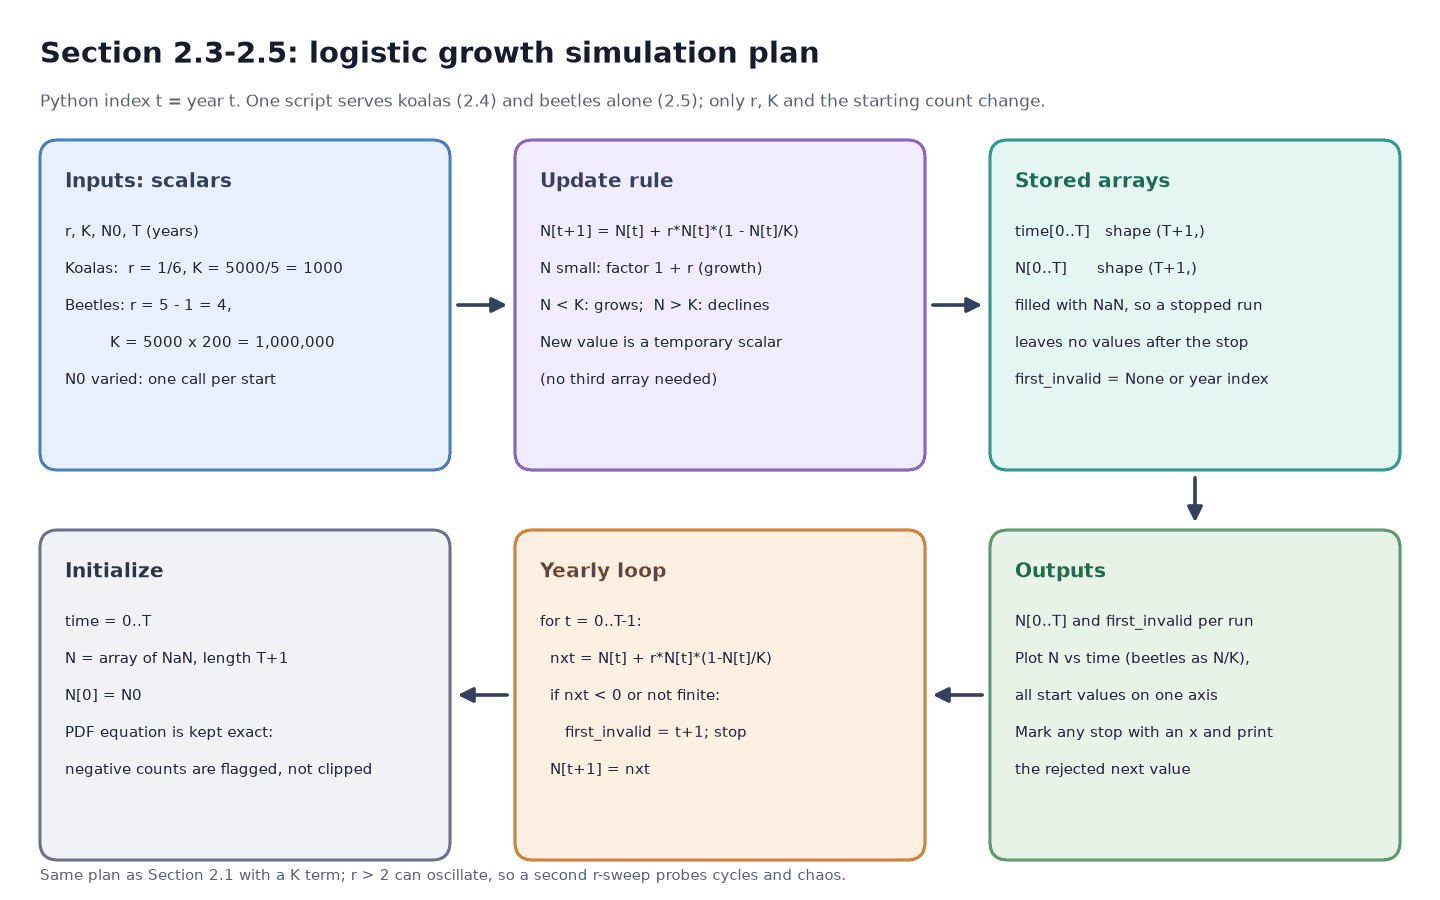

**Derivation / plan:** To be completed.

## 2.4 Characterize discrete logistic dynamics
Simulate several initial populations. How many types of behavior arise? Are there stable, indefinitely oscillating, or chaotic solutions? What in the model allows oscillations, and are they a numerical artifact or a plausible feature of nature? Use at most two plots, with multiple runs per plot if useful.

**Python implementation:** initial-condition experiments; at most two plots.

Koalas N0=50: first invalid year = None
Koalas N0=250: first invalid year = None
Koalas N0=800: first invalid year = None
Koalas N0=1000: first invalid year = None
Koalas N0=1500: first invalid year = None


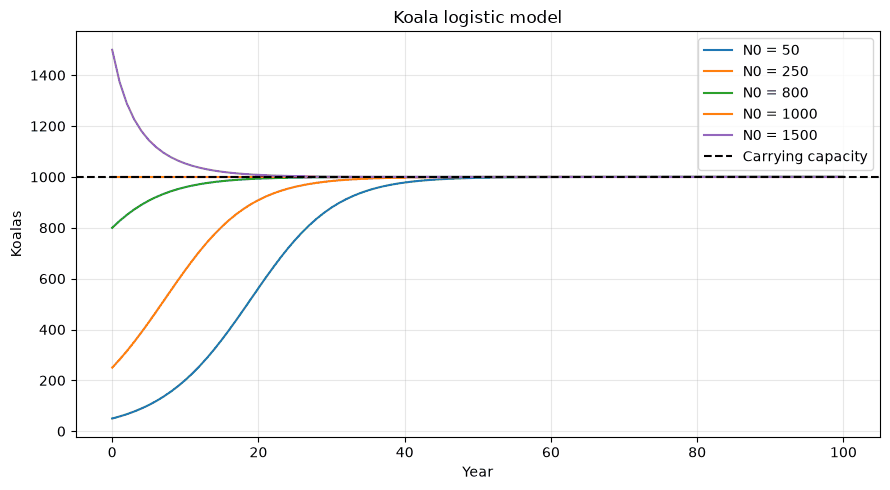

Koala carrying capacity = 1000


In [4]:
eucalyptus_trees = 5000
trees_per_koala = 5
K_koala = eucalyptus_trees / trees_per_koala

def simulate_logistic(initial, rate, capacity, years):
    # Keep the PDF's update exact; stop if a negative count would occur.
    values = np.full(years + 1, np.nan)
    values[0] = initial
    for t in range(years):
        n = values[t]
        next_n = n + rate * n * (1 - n / capacity)
        if not np.isfinite(next_n) or next_n < 0:
            return values, t + 1
        values[t + 1] = next_n
    return values, None

years_logistic = 100
time_logistic = np.arange(years_logistic + 1)
initial_koalas = [50, 250, 800, 1000, 1500]
fig, ax = plt.subplots(figsize=(9, 5))
for n0 in initial_koalas:
    trajectory, invalid_year = simulate_logistic(n0, r_koala, K_koala, years_logistic)
    ax.plot(time_logistic, trajectory, label=f"N0 = {n0}")
    print(f"Koalas N0={n0}: first invalid year = {invalid_year}")
ax.axhline(K_koala, color="black", linestyle="--", label="Carrying capacity")
ax.set(xlabel="Year", ylabel="Koalas", title="Koala logistic model")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Koala carrying capacity = {K_koala:g}")


r=1.5: last four values / K = [1. 1. 1. 1.]
r=2.2: last four values / K = [1.163 0.746 1.163 0.746]
r=2.5: last four values / K = [1.225 0.536 1.158 0.701]
r=2.9: last four values / K = [0.893 1.17  0.593 1.293]
r=3.2: next value after year 4 is negative; first invalid year = 5


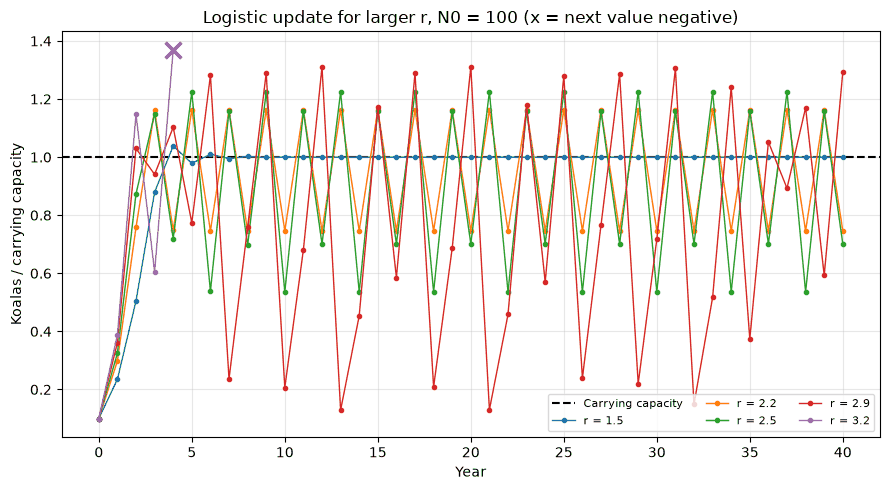

In [5]:
# Second plot for 2.4: the same update for larger growth rates. These r values are
# exploratory (the koala's own r is 1/6); K and the starting count are the koala values.
sweep_rates = [1.5, 2.2, 2.5, 2.9, 3.2]
sweep_years = 40
sweep_time = np.arange(sweep_years + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(1, color="black", linestyle="--", label="Carrying capacity")
for rate in sweep_rates:
    trajectory, invalid_year = simulate_logistic(100, rate, K_koala, sweep_years)
    line, = ax.plot(sweep_time, trajectory / K_koala, marker="o", markersize=3,
                    linewidth=1, label=f"r = {rate:g}")
    if invalid_year is None:
        print(f"r={rate:g}: last four values / K = {np.round(trajectory[-4:] / K_koala, 3)}")
    else:
        last = invalid_year - 1
        ax.plot(last, trajectory[last] / K_koala, "x", color=line.get_color(),
                markersize=11, markeredgewidth=2.5)
        print(f"r={rate:g}: next value after year {last} is negative; "
              f"first invalid year = {invalid_year}")
ax.set(xlabel="Year", ylabel="Koalas / carrying capacity",
       title="Logistic update for larger r, N0 = 100 (x = next value negative)")
ax.legend(ncol=3, fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 2.5 Beetles without koalas
Beetles live one year; half are female and each female produces ten offspring. Two hundred beetles can live on one eucalyptus tree. Find the beetle growth parameter and carrying capacity for the same 5,000-tree forest. Use the logistic equation to characterize beetles alone. Are the solutions qualitatively different from the koala model? Why?

The beetle-only simulation reuses the Section 2.3 array and loop plan with r = 4 and K = 1,000,000.

**Plan / response:** To be completed.

**Python implementation:** beetle-only simulations and plot.

Beetles B0=1: first invalid year = 10; rejected next value = -0.172 K
Beetles B0=100: first invalid year = 9; rejected next value = -1.870 K
Beetles B0=1,000: first invalid year = 6; rejected next value = -1.787 K
Beetles B0=100,000: first invalid year = 3; rejected next value = -1.184 K
Beetles B0=1,000,000: first invalid year = None


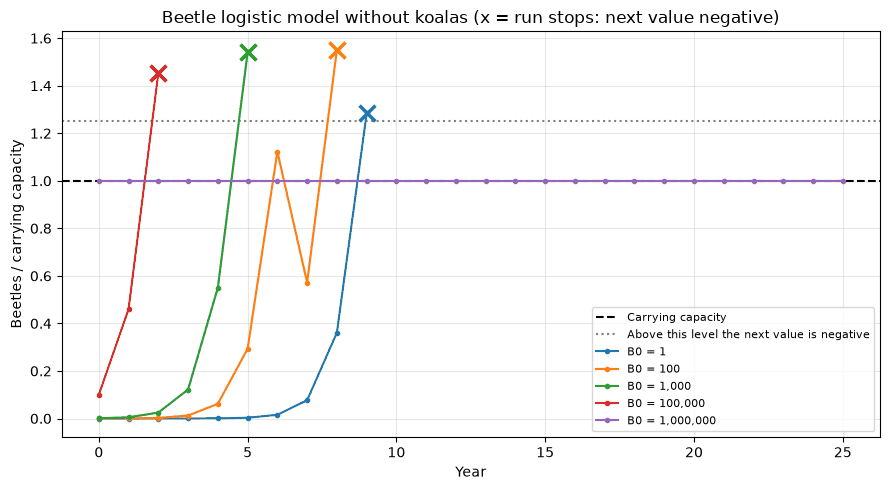

Beetle r = 4; carrying capacity = 1,000,000


In [6]:
female_beetle_fraction = 1 / 2
offspring_per_female = 10
# Adults die after reproducing; the young replace the current adults.
r_beetle = female_beetle_fraction * offspring_per_female - 1
beetles_per_tree = 200
K_beetle = eucalyptus_trees * beetles_per_tree
years_beetle = 25
time_beetle = np.arange(years_beetle + 1)
initial_beetles = [1, 100, 1000, 100_000, 1_000_000]
fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(1, color="black", linestyle="--", label="Carrying capacity")
ax.axhline((1 + r_beetle) / r_beetle, color="gray", linestyle=":",
           label="Above this level the next value is negative")
for b0 in initial_beetles:
    trajectory, invalid_year = simulate_logistic(b0, r_beetle, K_beetle, years_beetle)
    line, = ax.plot(time_beetle, trajectory / K_beetle, marker="o", markersize=3,
                    label=f"B0 = {b0:,}")
    if invalid_year is None:
        print(f"Beetles B0={b0:,}: first invalid year = None")
    else:
        last = invalid_year - 1
        n = trajectory[last]
        rejected = n + r_beetle * n * (1 - n / K_beetle)
        ax.plot(last, n / K_beetle, "x", color=line.get_color(),
                markersize=11, markeredgewidth=2.5)
        print(f"Beetles B0={b0:,}: first invalid year = {invalid_year}; "
              f"rejected next value = {rejected / K_beetle:.3f} K")
ax.set(xlabel="Year", ylabel="Beetles / carrying capacity",
       title="Beetle logistic model without koalas (x = run stops: next value negative)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Beetle r = {r_beetle:g}; carrying capacity = {K_beetle:,.0f}")


**Modeling note (beetles):** r_beetle = 4 comes from 10 offspring x 1/2 females = 5 young per beetle with every adult dying, so the net yearly factor is 5 = 1 + r. The PDF update is kept exact. For r = 4 it gives a negative next value whenever the population exceeds 1.25 K (dotted line), and the largest value the update can produce from a positive start is 1.5625 K. A run therefore stops at its first negative value (x) instead of being clipped or continued.

## 2.6 Koala–beetle competition: equations and plan
Use each species' logistic equation with a competitor term, converting the competitor population into equivalent consumers of eucalyptus. What are the two conversion constants, and what are the two coupled update equations? Explain why the constants differ.

Plan the two-population arrays and simultaneous yearly update. Attach or reproduce the requested plan.

**Heuristic array and computation plan (Python indices):**

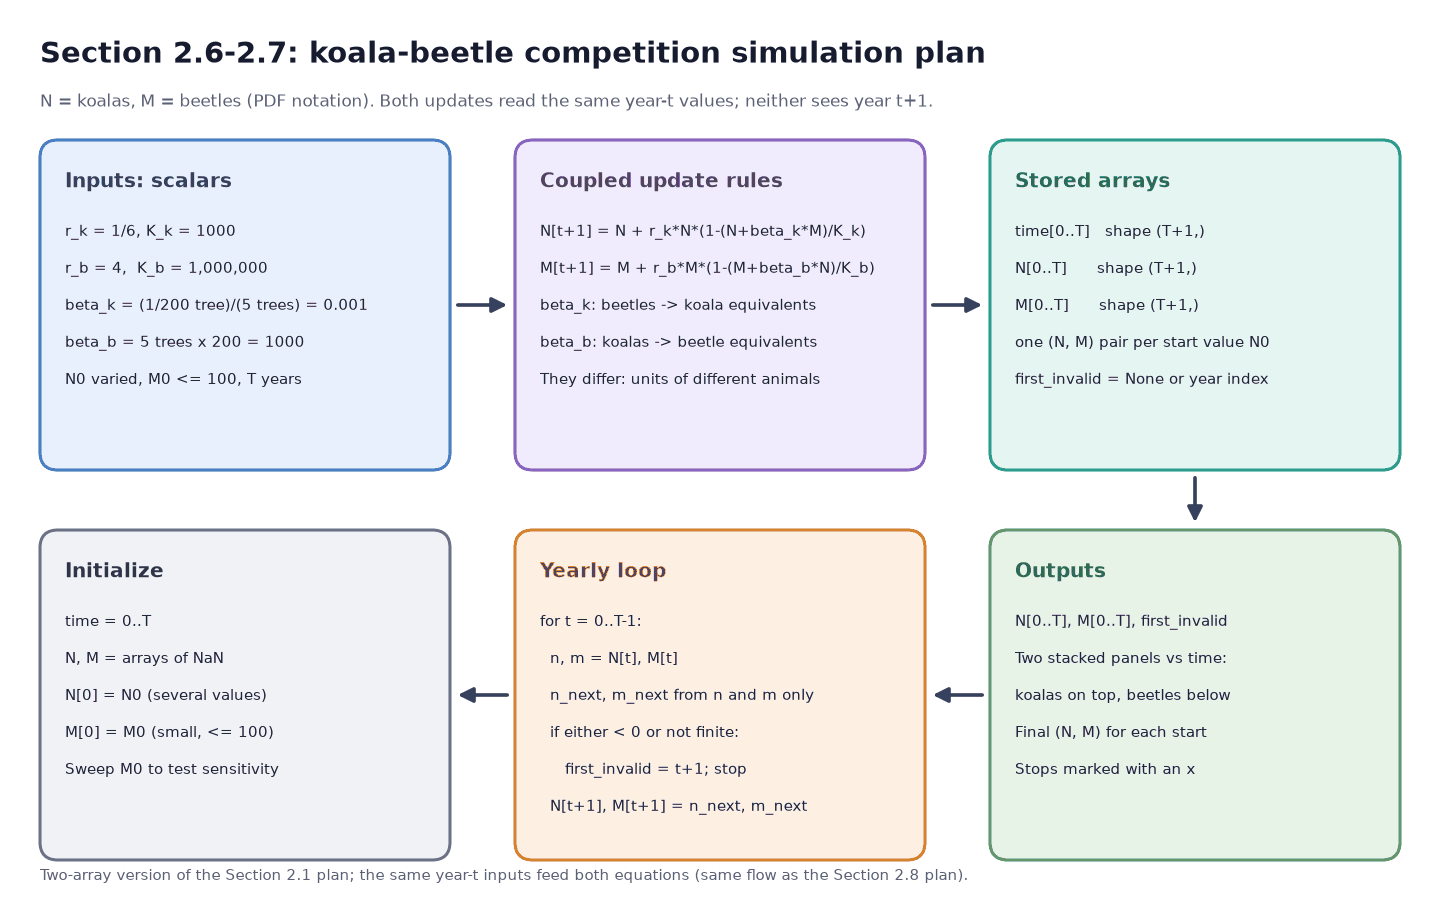

**Equations / plan:** To be completed.

## 2.7 Competition outcomes
Introduce a small beetle population (initial beetles no more than 100) at year zero. Simulate a variety of initial koala populations. How many distinct long-run equilibria occur? Show the relevant trajectories and discuss the outcomes.

**Python implementation:** coupled simulations and comparison plots.

Competition K0=100: first invalid year = 12
Competition K0=500: first invalid year = None
Competition K0=1000: first invalid year = None
Competition K0=1500: first invalid year = 1


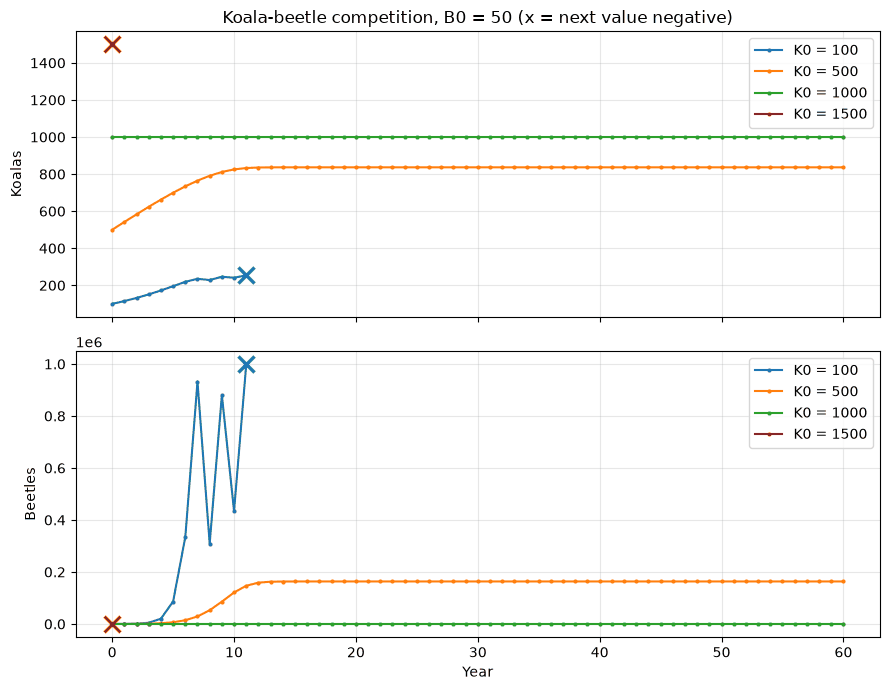

beta_koala = 0.001; beta_beetle = 1000

K0, B0: outcome (final koalas, final beetles, koalas + beta_koala * beetles)
K0=  100, B0=  1: koalas=   527.1, beetles=    472,868, koalas + beta_koala*beetles =   1000.0
K0=  100, B0= 10: koalas=   527.1, beetles=    472,868, koalas + beta_koala*beetles =   1000.0
K0=  100, B0= 50: stops in year 12
K0=  100, B0=100: stops in year 8
K0=  300, B0=  1: koalas=   740.5, beetles=    259,482, koalas + beta_koala*beetles =   1000.0
K0=  300, B0= 10: koalas=   651.7, beetles=    348,304, koalas + beta_koala*beetles =   1000.0
K0=  300, B0= 50: koalas=   590.9, beetles=    409,129, koalas + beta_koala*beetles =   1000.0
K0=  300, B0=100: koalas=   566.6, beetles=    433,440, koalas + beta_koala*beetles =   1000.0


K0=  500, B0=  1: koalas=   956.5, beetles=     43,540, koalas + beta_koala*beetles =   1000.0
K0=  500, B0= 10: koalas=   892.0, beetles=    107,960, koalas + beta_koala*beetles =   1000.0
K0=  500, B0= 50: koalas=   836.5, beetles=    163,523, koalas + beta_koala*beetles =   1000.0
K0=  500, B0=100: koalas=   811.0, beetles=    188,975, koalas + beta_koala*beetles =   1000.0
K0=  800, B0=  1: koalas=   999.9, beetles=         91, koalas + beta_koala*beetles =   1000.0
K0=  800, B0= 10: koalas=   999.1, beetles=        896, koalas + beta_koala*beetles =   1000.0


K0=  800, B0= 50: koalas=   995.8, beetles=      4,167, koalas + beta_koala*beetles =   1000.0
K0=  800, B0=100: koalas=   992.3, beetles=      7,704, koalas + beta_koala*beetles =   1000.0
K0= 1000, B0=  1: koalas=  1000.0, beetles=          1, koalas + beta_koala*beetles =   1000.0
K0= 1000, B0= 10: koalas=  1000.0, beetles=         10, koalas + beta_koala*beetles =   1000.0
K0= 1000, B0= 50: koalas=  1000.0, beetles=         50, koalas + beta_koala*beetles =   1000.0
K0= 1000, B0=100: koalas=   999.9, beetles=        100, koalas + beta_koala*beetles =   1000.0


K0= 1200, B0=  1: koalas=  1000.0, beetles=          0, koalas + beta_koala*beetles =   1000.0
K0= 1200, B0= 10: koalas=  1000.0, beetles=          0, koalas + beta_koala*beetles =   1000.0
K0= 1200, B0= 50: koalas=  1000.0, beetles=          0, koalas + beta_koala*beetles =   1000.0
K0= 1200, B0=100: koalas=  1000.0, beetles=          0, koalas + beta_koala*beetles =   1000.0
K0= 1500, B0=  1: stops in year 1
K0= 1500, B0= 10: stops in year 1
K0= 1500, B0= 50: stops in year 1
K0= 1500, B0=100: stops in year 1


In [7]:
# Convert beetle consumption to koala units and vice versa.
beta_koala = (1 / beetles_per_tree) / trees_per_koala
beta_beetle = trees_per_koala * beetles_per_tree

def simulate_competition(koalas_initial, beetles_initial, years):
    koalas = np.full(years + 1, np.nan)
    beetles = np.full(years + 1, np.nan)
    koalas[0], beetles[0] = koalas_initial, beetles_initial
    for t in range(years):
        k, b = koalas[t], beetles[t]
        # Simultaneous updates use only year-t values.
        k_next = k + r_koala * k * (1 - (k + beta_koala * b) / K_koala)
        b_next = b + r_beetle * b * (1 - (b + beta_beetle * k) / K_beetle)
        if not np.all(np.isfinite([k_next, b_next])) or min(k_next, b_next) < 0:
            return koalas, beetles, t + 1
        koalas[t + 1], beetles[t + 1] = k_next, b_next
    return koalas, beetles, None

years_competition = 60
time_competition = np.arange(years_competition + 1)
initial_koalas_competition = [100, 500, 1000, 1500]
initial_beetles_competition = 50  # Introduced at year 0; no more than 100.
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for k0 in initial_koalas_competition:
    koalas, beetles, invalid_year = simulate_competition(
        k0, initial_beetles_competition, years_competition)
    line, = axes[0].plot(time_competition, koalas, marker="o", markersize=2,
                         label=f"K0 = {k0}")
    axes[1].plot(time_competition, beetles, marker="o", markersize=2,
                 color=line.get_color(), label=f"K0 = {k0}")
    if invalid_year is not None:
        last = invalid_year - 1
        for ax, series in ((axes[0], koalas), (axes[1], beetles)):
            ax.plot(last, series[last], "x", color=line.get_color(),
                    markersize=11, markeredgewidth=2.5)
    print(f"Competition K0={k0}: first invalid year = {invalid_year}")
axes[0].set(ylabel="Koalas",
            title="Koala-beetle competition, B0 = 50 (x = next value negative)")
axes[1].set(xlabel="Year", ylabel="Beetles")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"beta_koala = {beta_koala:g}; beta_beetle = {beta_beetle:g}")

# Sensitivity to the introduced beetle count (the PDF allows up to 100) and to the
# start. Runs that do not stop are followed for 2,000 years to see where they settle.
print("\nK0, B0: outcome (final koalas, final beetles, koalas + beta_koala * beetles)")
for k0 in [100, 300, 500, 800, 1000, 1200, 1500]:
    for b0 in [1, 10, 50, 100]:
        koalas, beetles, invalid_year = simulate_competition(k0, b0, 2000)
        if invalid_year is not None:
            print(f"K0={k0:5d}, B0={b0:3d}: stops in year {invalid_year}")
        else:
            print(f"K0={k0:5d}, B0={b0:3d}: koalas={koalas[-1]:8.1f}, beetles={beetles[-1]:11,.0f}, "
                  f"koalas + beta_koala*beetles = {koalas[-1] + beta_koala * beetles[-1]:8.1f}")


**Modeling note (competition):** beta_koala x beta_beetle = 1 and K_beetle = beta_beetle x K_koala, so the koala and beetle balance conditions describe the same line, koalas + beta_koala x beetles = K_koala. In the table above, every run that does not stop settles on that line, at a point that depends on its start. The stops come from the beetles' r = 4 overshoot: in the first year when K0 > 1250 (the koala load alone exceeds 1.25 K_beetle), or after a few oscillating years when beetle growth overshoots (K0 = 100 with B0 of 50 or more).

## 2.8 Koala–snake predator–prey model: equations and plan
Replace beetles with tree snakes. Each snake eats one koala per month. Modify the koala equation for annual predation. One-quarter of snakes are mature females, each reproducing successfully in a year with probability one-eighth; formulate the snake update analogous to the logistic equation, with snake carrying capacity depending on koala population. State any additional assumptions.

Plan the population arrays and yearly calculation flow. Attach or reproduce the requested plan.

**Array and computation plan:**

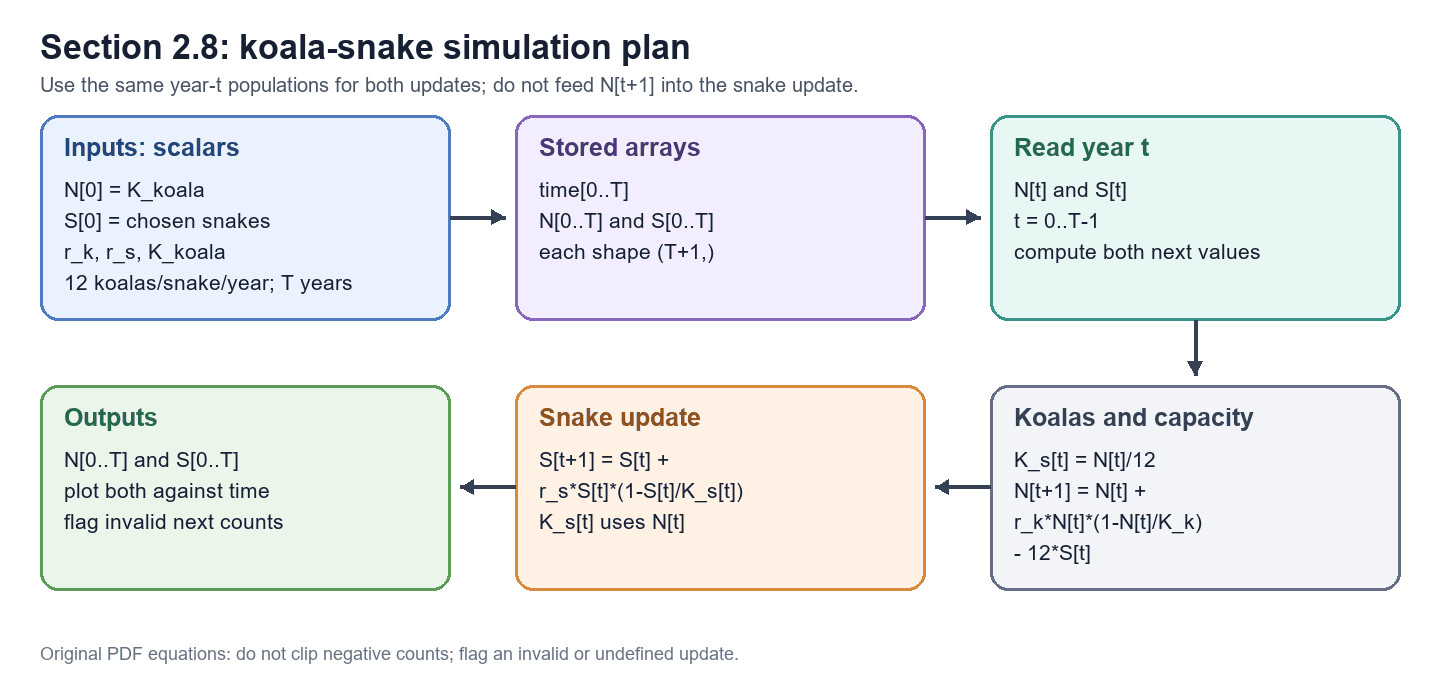

**Equations / plan:** To be completed.

## 2.9 Predator–prey outcomes and thresholds
Start koalas at their carrying capacity. Vary the number of snakes introduced at year zero. How does the system respond? Are there introduction thresholds where a small change in initial snakes causes a large change in the long-run outcome? Plot and discuss the evidence.

**Python implementation:** predator–prey simulations and plots.

Predator-prey S0=0: first invalid year = None
Predator-prey S0=1: first invalid year = 70
Predator-prey S0=2: first invalid year = 47
Predator-prey S0=5: first invalid year = 21
Predator-prey S0=10: first invalid year = 10
Predator-prey S0=20: first invalid year = 5


Predator-prey S0=40: first invalid year = 3
Predator-prey S0=80: first invalid year = 2


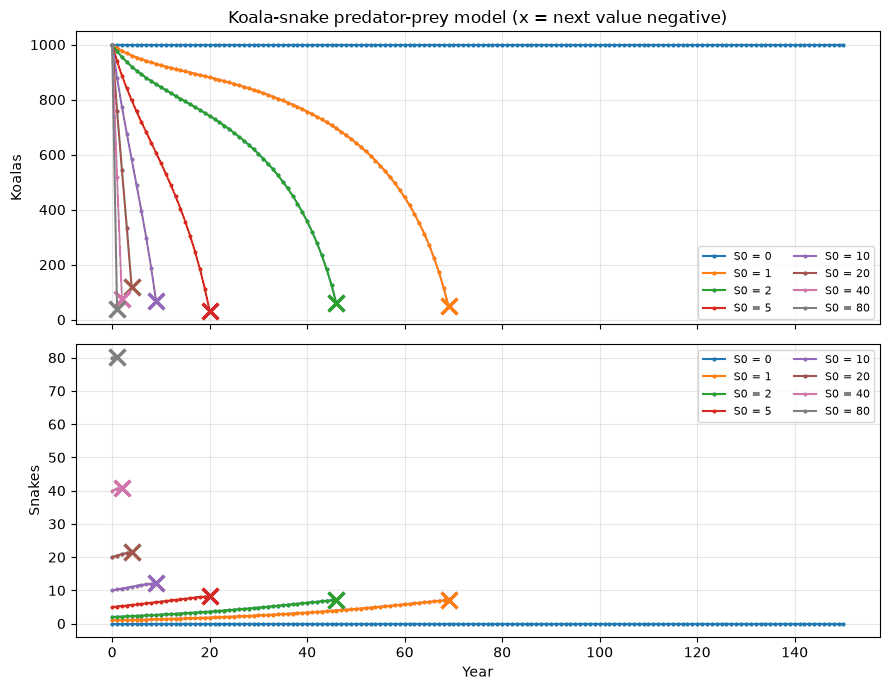

Introductions with no invalid update in 150 years: S0 = [0]
Introductions that collapse: 100 of 101; first invalid year for S0 = 1..5: [70, 47, 34, 26, 21]
Largest steady annual kill the koala growth term can replace: r*K/4 = 41.7 koalas/year = 3.47 snakes


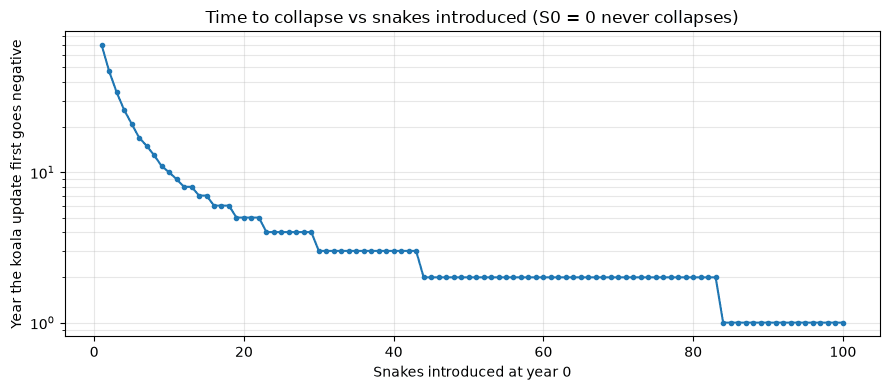

In [8]:
female_snake_fraction = 1 / 4
snake_birth_probability = 1 / 8
r_snake = female_snake_fraction * snake_birth_probability
koalas_eaten_per_snake_year = 12

def simulate_predator_prey(snakes_initial, years):
    koalas = np.full(years + 1, np.nan)
    snakes = np.full(years + 1, np.nan)
    koalas[0], snakes[0] = K_koala, snakes_initial
    for t in range(years):
        k, s = koalas[t], snakes[t]
        snake_capacity = k / koalas_eaten_per_snake_year
        if snake_capacity == 0 and s > 0:
            return koalas, snakes, t + 1  # Snake equation is undefined.
        k_next = k + r_koala * k * (1 - k / K_koala) - 12 * s
        s_next = (s + r_snake * s * (1 - s / snake_capacity)
                  if snake_capacity > 0 else 0.0)
        if not np.all(np.isfinite([k_next, s_next])) or min(k_next, s_next) < 0:
            return koalas, snakes, t + 1
        koalas[t + 1], snakes[t + 1] = k_next, s_next
    return koalas, snakes, None

years_predator = 150
time_predator = np.arange(years_predator + 1)
initial_snakes = [0, 1, 2, 5, 10, 20, 40, 80]
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for s0 in initial_snakes:
    koalas, snakes, invalid_year = simulate_predator_prey(s0, years_predator)
    line, = axes[0].plot(time_predator, koalas, marker="o", markersize=2,
                         label=f"S0 = {s0}")
    axes[1].plot(time_predator, snakes, marker="o", markersize=2,
                 color=line.get_color(), label=f"S0 = {s0}")
    if invalid_year is not None:
        last = invalid_year - 1
        for ax, series in ((axes[0], koalas), (axes[1], snakes)):
            ax.plot(last, series[last], "x", color=line.get_color(),
                    markersize=11, markeredgewidth=2.5)
    print(f"Predator-prey S0={s0}: first invalid year = {invalid_year}")
axes[0].set(ylabel="Koalas",
            title="Koala-snake predator-prey model (x = next value negative)")
axes[1].set(xlabel="Year", ylabel="Snakes")
for ax in axes:
    ax.legend(ncol=2, fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Scan introductions one snake at a time. Outcome = does the koala update ever go
# negative within 150 years, and if so when (time to collapse).
snake_grid = np.arange(0, 101)
first_invalid = [
    simulate_predator_prey(int(s0), years_predator)[2] for s0 in snake_grid
]
survivors = [int(s) for s, y in zip(snake_grid, first_invalid) if y is None]
collapse = [(int(s), y) for s, y in zip(snake_grid, first_invalid) if y is not None]
print(f"Introductions with no invalid update in {years_predator} years: S0 = {survivors}")
print(f"Introductions that collapse: {len(collapse)} of {len(snake_grid)}; "
      f"first invalid year for S0 = 1..5: {[y for _, y in collapse[:5]]}")
max_harvest = r_koala * K_koala / 4
print(f"Largest steady annual kill the koala growth term can replace: r*K/4 = "
      f"{max_harvest:.1f} koalas/year = {max_harvest / koalas_eaten_per_snake_year:.2f} snakes")
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy([s for s, _ in collapse], [y for _, y in collapse], ".-")
ax.set(xlabel="Snakes introduced at year 0",
       ylabel="Year the koala update first goes negative",
       title="Time to collapse vs snakes introduced (S0 = 0 never collapses)")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()


**Modeling assumption (predator-prey):** the PDF only says K_snakes is a function of N_t. This notebook uses K_snakes(N_t) = N_t / 12, the number of snakes the current koalas could feed at 12 koalas per snake-year; koalas eaten use the same year-t snake count (S_t) as the PDF states. At that capacity the snakes would eat the entire koala population each year, which shapes the collapse results above. A different capacity function would change them.

### 2.9a Zero-floor sensitivity (modified model)
This optional comparison leaves the original simulations above intact. After each exact annual update, replace a negative population with zero. Apply the rule to beetles alone, both species in competition, and koalas and snakes in predator-prey runs. If koalas are already zero, set next year's snake population to zero because the snake carrying-capacity expression would otherwise divide by zero. These are added boundary rules, not rules specified in the PDF.


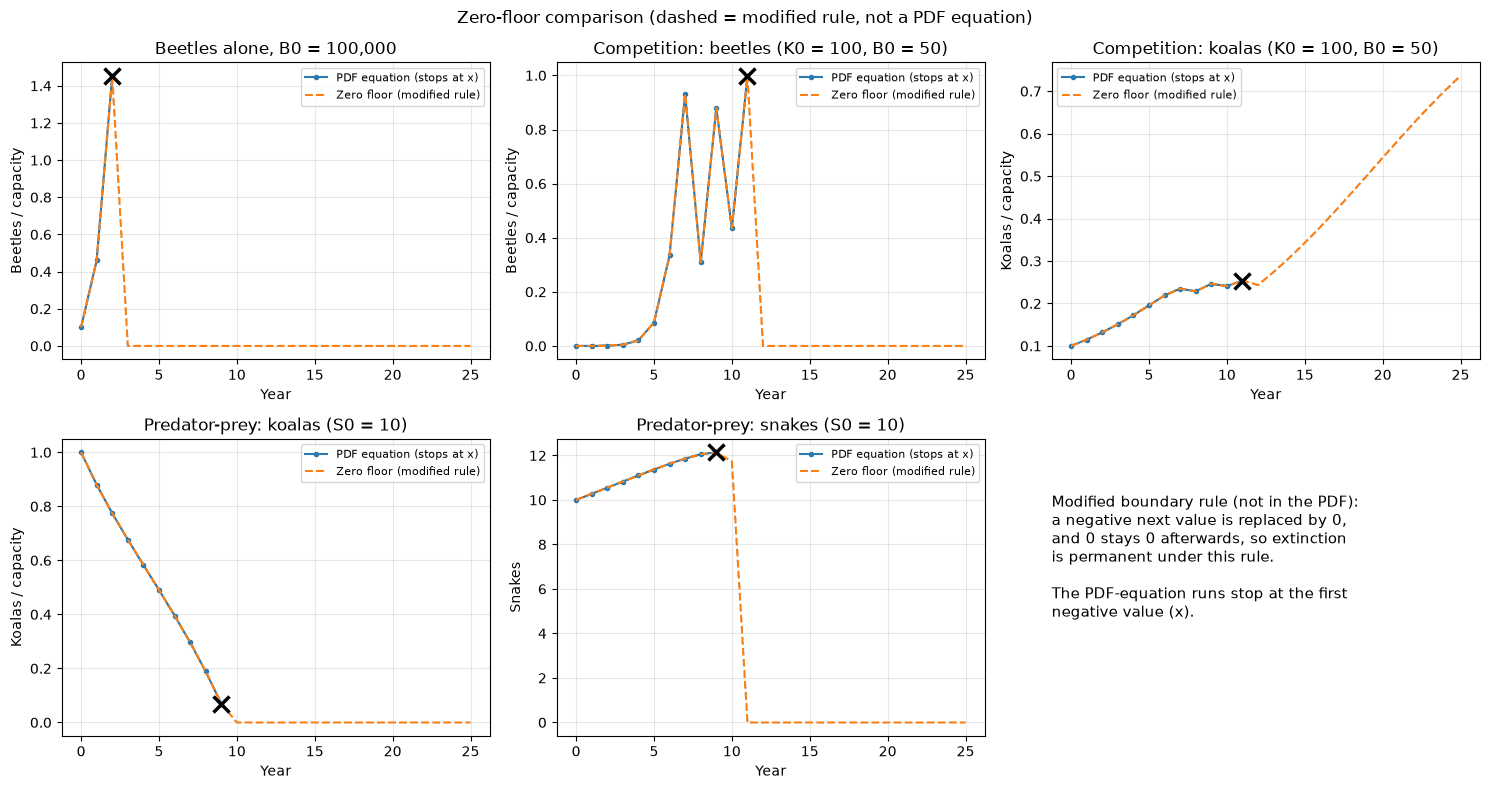

In [9]:
def simulate_logistic_floor(initial, rate, capacity, years):
    values = np.empty(years + 1)
    values[0] = initial
    for t in range(years):
        n = values[t]
        raw_next = n + rate * n * (1 - n / capacity)
        values[t + 1] = max(0.0, raw_next)
    return values

def simulate_competition_floor(koalas_initial, beetles_initial, years):
    koalas = np.empty(years + 1)
    beetles = np.empty(years + 1)
    koalas[0], beetles[0] = koalas_initial, beetles_initial
    for t in range(years):
        k, b = koalas[t], beetles[t]
        k_raw = k + r_koala * k * (1 - (k + beta_koala * b) / K_koala)
        b_raw = b + r_beetle * b * (1 - (b + beta_beetle * k) / K_beetle)
        koalas[t + 1] = max(0.0, k_raw)
        beetles[t + 1] = max(0.0, b_raw)
    return koalas, beetles

def simulate_predator_prey_floor(snakes_initial, years):
    koalas = np.empty(years + 1)
    snakes = np.empty(years + 1)
    koalas[0], snakes[0] = K_koala, snakes_initial
    for t in range(years):
        k, s = koalas[t], snakes[t]
        k_raw = k + r_koala * k * (1 - k / K_koala) - 12 * s
        snake_capacity = k / koalas_eaten_per_snake_year
        s_raw = (s + r_snake * s * (1 - s / snake_capacity)
                 if snake_capacity > 0 else 0.0)
        koalas[t + 1] = max(0.0, k_raw)
        snakes[t + 1] = max(0.0, s_raw)
    return koalas, snakes

comparison_years = 25
comparison_time = np.arange(comparison_years + 1)
beetles_original, _ = simulate_logistic(100_000, r_beetle, K_beetle, comparison_years)
beetles_floor = simulate_logistic_floor(100_000, r_beetle, K_beetle, comparison_years)
koalas_original, beetles_comp_original, _ = simulate_competition(100, 50, comparison_years)
koalas_floor, beetles_comp_floor = simulate_competition_floor(100, 50, comparison_years)
koalas_pred_original, snakes_pred_original, _ = simulate_predator_prey(10, comparison_years)
koalas_pred_floor, snakes_pred_floor = simulate_predator_prey_floor(10, comparison_years)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

def compare(ax, original, floored, scale, title, ylabel):
    """Original PDF run (stops at x) against the zero-floor run (dashed, modified)."""
    ax.plot(comparison_time, original / scale, marker="o", markersize=3,
            label="PDF equation (stops at x)")
    ax.plot(comparison_time, floored / scale, "--", label="Zero floor (modified rule)")
    valid = np.flatnonzero(~np.isnan(original))
    if valid[-1] < len(original) - 1:
        ax.plot(valid[-1], original[valid[-1]] / scale, "x", color="black",
                markersize=11, markeredgewidth=2.5)
    ax.set(title=title, ylabel=ylabel, xlabel="Year")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

compare(axes[0, 0], beetles_original, beetles_floor, K_beetle,
        "Beetles alone, B0 = 100,000", "Beetles / capacity")
compare(axes[0, 1], beetles_comp_original, beetles_comp_floor, K_beetle,
        "Competition: beetles (K0 = 100, B0 = 50)", "Beetles / capacity")
compare(axes[0, 2], koalas_original, koalas_floor, K_koala,
        "Competition: koalas (K0 = 100, B0 = 50)", "Koalas / capacity")
compare(axes[1, 0], koalas_pred_original, koalas_pred_floor, K_koala,
        "Predator-prey: koalas (S0 = 10)", "Koalas / capacity")
compare(axes[1, 1], snakes_pred_original, snakes_pred_floor, 1,
        "Predator-prey: snakes (S0 = 10)", "Snakes")
axes[1, 2].axis("off")
axes[1, 2].text(0.0, 0.6,
                "Modified boundary rule (not in the PDF):\n"
                "a negative next value is replaced by 0,\n"
                "and 0 stays 0 afterwards, so extinction\n"
                "is permanent under this rule.\n\n"
                "The PDF-equation runs stop at the first\n"
                "negative value (x).",
                fontsize=11, va="center")
fig.suptitle("Zero-floor comparison (dashed = modified rule, not a PDF equation)")
plt.tight_layout()
plt.show()


### 2.9b Limited-kills sensitivity (modified predator-prey model)
Keep the original predator-prey equations above for comparison. Here the annual kill count is the smaller of 12 times the current snake population and the koalas available after that year's logistic growth. This changes only the predation term while prey remain positive. If prey have reached zero, set next year's snakes to zero because their carrying capacity is zero. The snake update otherwise remains unchanged; the simulation still stops if that update becomes negative. For nonnegative available koalas, both fixes yield the same next koala count; limited kills additionally records how many koalas were actually eaten. The third comparison plot shows requested versus actual kills.


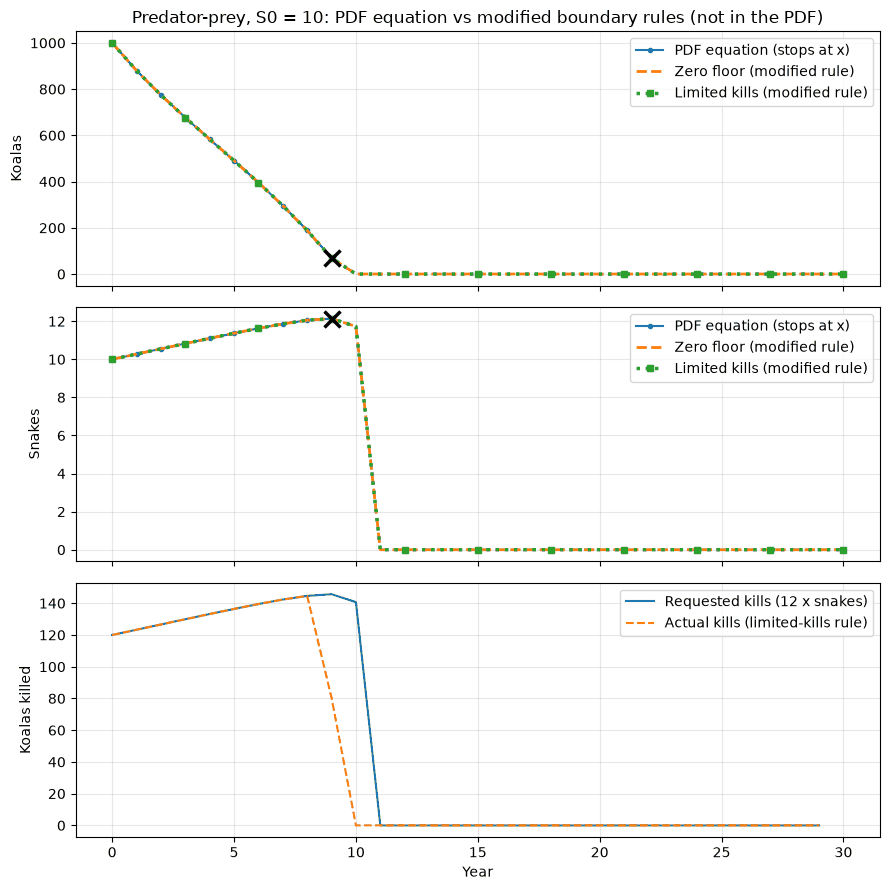

PDF equation first invalid year: 10
Limited-kills first invalid year: None
Years when kills were capped: [9, 10]
Zero floor and limited kills give identical koala and snake paths for 97 of 97 introductions where limited kills completes.
Limited kills stops (snake update negative) for (S0, year): [(43, 3), (81, 2), (82, 2), (83, 2)]


In [10]:
def simulate_predator_prey_limited_kills(snakes_initial, years):
    koalas = np.full(years + 1, np.nan)
    snakes = np.full(years + 1, np.nan)
    kills = np.full(years, np.nan)
    koalas[0], snakes[0] = K_koala, snakes_initial
    for t in range(years):
        k, s = koalas[t], snakes[t]
        available = k + r_koala * k * (1 - k / K_koala)
        if available < 0:
            return koalas, snakes, kills, t + 1
        kills[t] = min(12 * s, available)
        k_next = available - kills[t]
        snake_capacity = k / koalas_eaten_per_snake_year
        s_next = (s + r_snake * s * (1 - s / snake_capacity)
                  if snake_capacity > 0 else 0.0)
        if not np.isfinite(s_next) or s_next < 0:
            return koalas, snakes, kills, t + 1
        koalas[t + 1], snakes[t + 1] = k_next, s_next
    return koalas, snakes, kills, None

limited_years = 30
limited_time = np.arange(limited_years + 1)
snakes_initial_comparison = 10
k_original, s_original, original_invalid = simulate_predator_prey(
    snakes_initial_comparison, limited_years)
k_floor, s_floor = simulate_predator_prey_floor(
    snakes_initial_comparison, limited_years)
k_limited, s_limited, actual_kills, limited_invalid = (
    simulate_predator_prey_limited_kills(snakes_initial_comparison, limited_years))
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
for ax, original, floor, limited, label in (
    (axes[0], k_original, k_floor, k_limited, "Koalas"),
    (axes[1], s_original, s_floor, s_limited, "Snakes"),
):
    ax.plot(limited_time, original, marker="o", markersize=3, label="PDF equation (stops at x)")
    ax.plot(limited_time, floor, "--", linewidth=2, label="Zero floor (modified rule)")
    ax.plot(limited_time, limited, ":", linewidth=2.5, marker="s", markersize=4,
            markevery=3, label="Limited kills (modified rule)")
    valid = np.flatnonzero(~np.isnan(original))
    if valid[-1] < len(original) - 1:
        ax.plot(valid[-1], original[valid[-1]], "x", color="black",
                markersize=11, markeredgewidth=2.5)
    ax.set_ylabel(label)
    ax.legend()
    ax.grid(alpha=0.3)
axes[0].set_title("Predator-prey, S0 = 10: PDF equation vs modified boundary rules "
                  "(not in the PDF)")
axes[2].plot(limited_time[:-1], 12 * s_limited[:-1], label="Requested kills (12 x snakes)")
axes[2].plot(limited_time[:-1], actual_kills, "--", label="Actual kills (limited-kills rule)")
axes[2].set_ylabel("Koalas killed")
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_xlabel("Year")
plt.tight_layout()
plt.show()
capped_years = np.flatnonzero(actual_kills < 12 * s_limited[:-1] - 1e-9)
print(f"PDF equation first invalid year: {original_invalid}")
print(f"Limited-kills first invalid year: {limited_invalid}")
print(f"Years when kills were capped: {capped_years.tolist()}")

# Consistency of the two modified rules over every introduction from 0 to 100 snakes.
agree, stopped = 0, []
for s0 in range(101):
    kf, sf = simulate_predator_prey_floor(s0, limited_years)
    kl, sl, _, invalid = simulate_predator_prey_limited_kills(s0, limited_years)
    if invalid is not None:
        stopped.append((s0, invalid))
    elif np.allclose(kf, kl) and np.allclose(sf, sl):
        agree += 1
print(f"Zero floor and limited kills give identical koala and snake paths for {agree} of "
      f"{101 - len(stopped)} introductions where limited kills completes.")
print(f"Limited kills stops (snake update negative) for (S0, year): {stopped}")


## 2.10 Don’t compute, just think
Would an introduced snake prefer beetles to be introduced? Would a beetle prefer snakes to be introduced? Discuss both questions briefly, using the food-web relationships rather than another computation.

**Response:** To be completed.

# 3. Tracking snow leopards
## 3.1 Movement model: design and short check
Model a 10 × 10 grid with daily steps. A leopard must move to one of the adjacent eight cells that remains inside the habitat, choosing uniformly among available cells. Plan position and time storage, boundary handling, random movement, and reusable functions; include a diagram of dimensions, indices, and decision order. Test each part separately.

Run and inspect a single leopard for fewer than ten steps, then produce the requested ten-day script output.

**Heuristic plan: dimensions, indices, functions and order of decisions:**

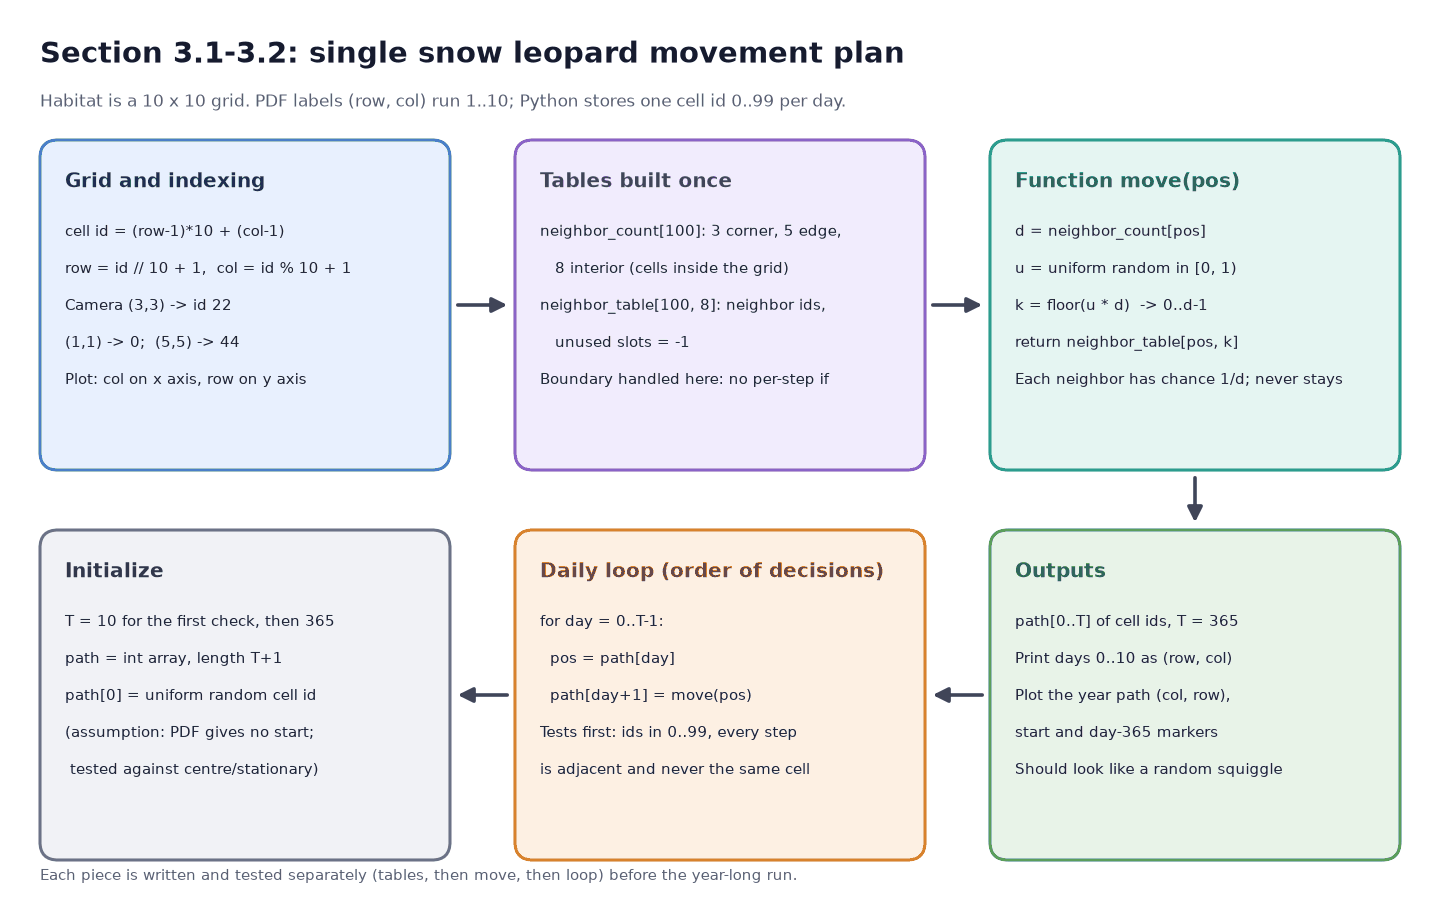

**Plan:** To be completed.

**Python implementation:** single-leopard movement and short-run checks.

In [11]:
import numpy as np
import matplotlib.pyplot as plt

GRID_SIZE = 10
neighbor_table = np.full((GRID_SIZE**2, 8), -1, dtype=np.int16)
neighbor_count = np.zeros(GRID_SIZE**2, dtype=np.int8)
for row in range(GRID_SIZE):
    for col in range(GRID_SIZE):
        cell = row * GRID_SIZE + col
        options = [
            (row + dr) * GRID_SIZE + (col + dc)
            for dr in (-1, 0, 1) for dc in (-1, 0, 1)
            if (dr, dc) != (0, 0)
            and 0 <= row + dr < GRID_SIZE
            and 0 <= col + dc < GRID_SIZE
        ]
        neighbor_count[cell] = len(options)
        neighbor_table[cell, :len(options)] = options

def move_positions(positions, rng):
    # Works for one cell or an array of independent animal positions.
    degrees = neighbor_count[positions]
    choices = (rng.random(np.shape(positions)) * degrees).astype(int)
    return neighbor_table[positions, choices]

assert set(neighbor_table[0, :neighbor_count[0]]) == {1, 10, 11}
assert neighbor_count[0] == 3 and neighbor_count[5] == 5
assert neighbor_count[55] == 8
short_rng = np.random.default_rng(42)
short_path = np.empty(11, dtype=np.int16)  # Day 0 plus ten daily moves.
# Initial position is uniform over the 100 habitat cells.
short_path[0] = short_rng.integers(GRID_SIZE**2)
for day in range(10):
    short_path[day + 1] = move_positions(short_path[day], short_rng)
assert np.all(short_path[1:] != short_path[:-1])
assert all(next_cell in neighbor_table[cell, :neighbor_count[cell]]
           for cell, next_cell in zip(short_path[:-1], short_path[1:]))
print("day, MATLAB-style row, MATLAB-style column")
print(np.column_stack((np.arange(11), short_path // GRID_SIZE + 1,
                       short_path % GRID_SIZE + 1)))


day, MATLAB-style row, MATLAB-style column
[[ 0  1  9]
 [ 1  2  8]
 [ 2  3  8]
 [ 3  4  7]
 [ 4  3  6]
 [ 5  4  7]
 [ 6  5  7]
 [ 7  6  7]
 [ 8  5  7]
 [ 9  5  6]
 [10  4  7]]


**Assumption (starting position):** the PDF does not give a starting cell. Every leopard, in every simulation run, starts in a uniformly random one of the 100 habitat cells. The check at the end of 3.5 repeats the population estimate with stationary and centre starts.

## 3.2 One leopard over a year
Run the checked movement model for 365 days. Plot its path through the 10 × 10 region and check that the path behaves as expected.

**Python implementation:** year-long single path and plot.

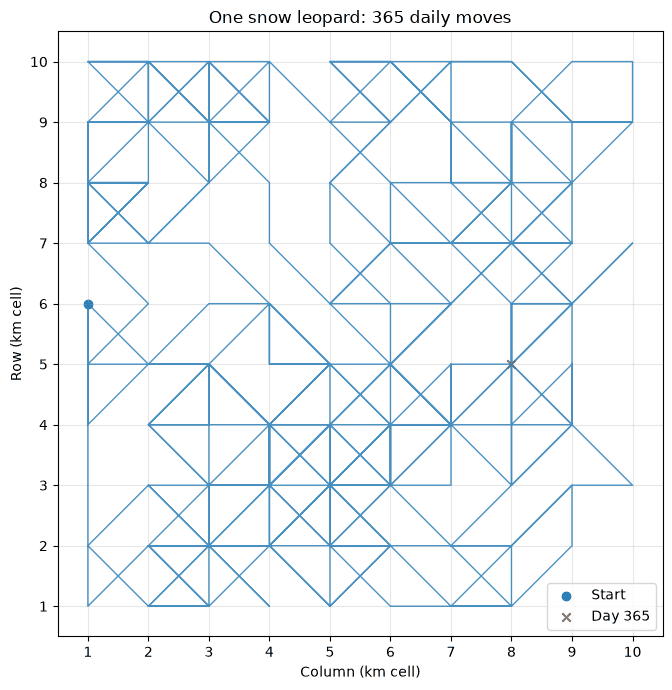

In [12]:
study_days = 365
year_rng = np.random.default_rng(43)
single_year_path = np.empty(study_days + 1, dtype=np.int16)
single_year_path[0] = year_rng.integers(GRID_SIZE**2)
for day in range(study_days):
    single_year_path[day + 1] = move_positions(single_year_path[day], year_rng)
assert np.all(single_year_path[1:] != single_year_path[:-1])
assert np.all((single_year_path >= 0) & (single_year_path < GRID_SIZE**2))
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(single_year_path % GRID_SIZE + 1,
        single_year_path // GRID_SIZE + 1, linewidth=1, alpha=0.8)
ax.scatter(single_year_path[0] % GRID_SIZE + 1,
           single_year_path[0] // GRID_SIZE + 1, marker="o", label="Start")
ax.scatter(single_year_path[-1] % GRID_SIZE + 1,
           single_year_path[-1] // GRID_SIZE + 1, marker="x", label="Day 365")
ax.set(xlabel="Column (km cell)", ylabel="Row (km cell)",
       xlim=(0.5, 10.5), ylim=(0.5, 10.5),
       title="One snow leopard: 365 daily moves")
ax.set_aspect("equal")
ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 11))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## 3.3 Multiple leopards
Generalize to a parameterized population N; multiple animals may occupy one cell. Check N = 2 before larger populations. Plot the 365-day paths for N > 2 with a different color for each animal.

**Python implementation:** multiple-leopard movement and paths.

**Heuristic plan for 3.3-3.6 (N leopards, camera, Monte Carlo):**

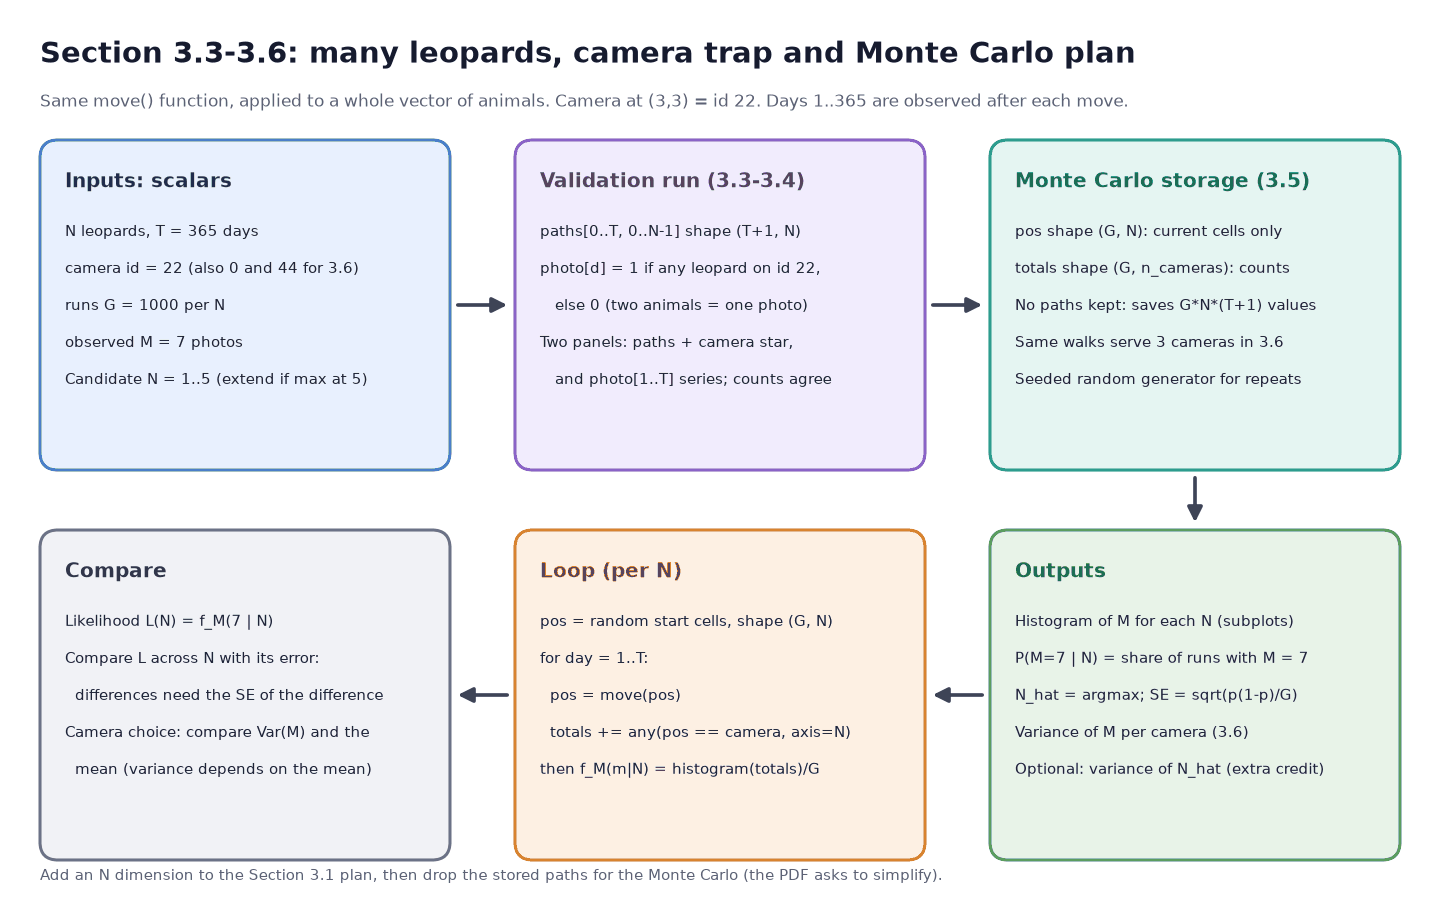


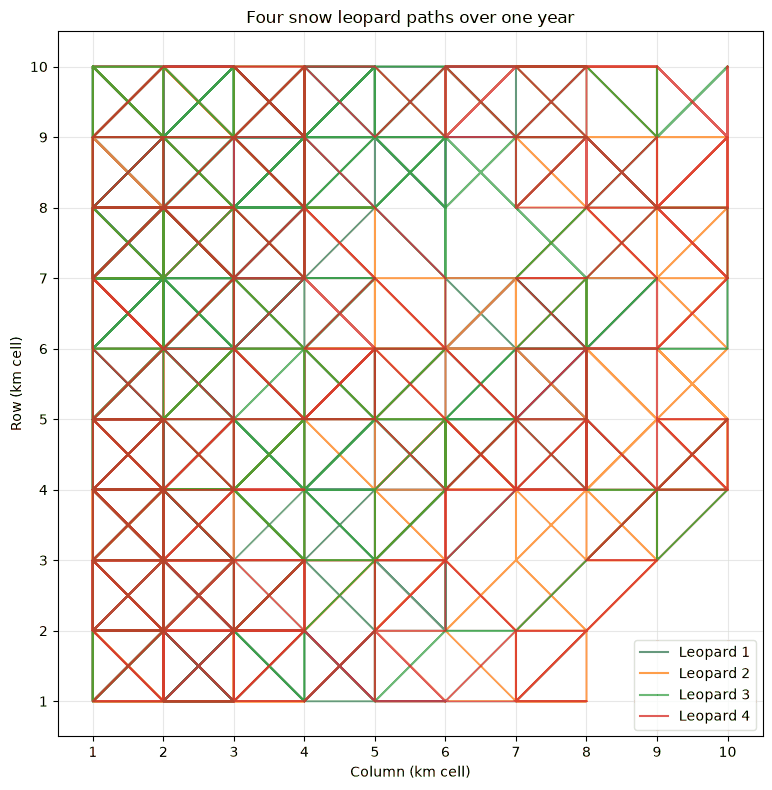

In [13]:
def simulate_paths(n_leopards, days, rng):
    paths = np.empty((days + 1, n_leopards), dtype=np.int16)
    paths[0] = rng.integers(GRID_SIZE**2, size=n_leopards)
    for day in range(days):
        paths[day + 1] = move_positions(paths[day], rng)
    return paths

paths_two = simulate_paths(2, study_days, np.random.default_rng(44))
assert paths_two.shape == (study_days + 1, 2)
assert np.all(paths_two[1:] != paths_two[:-1])
paths_multi = simulate_paths(4, study_days, np.random.default_rng(45))
assert np.all((paths_multi >= 0) & (paths_multi < GRID_SIZE**2))
fig, ax = plt.subplots(figsize=(8, 8))
for animal in range(paths_multi.shape[1]):
    ax.plot(paths_multi[:, animal] % GRID_SIZE + 1,
            paths_multi[:, animal] // GRID_SIZE + 1,
            alpha=0.75, label=f"Leopard {animal + 1}")
ax.set(xlabel="Column (km cell)", ylabel="Row (km cell)",
       xlim=(0.5, 10.5), ylim=(0.5, 10.5),
       title="Four snow leopard paths over one year")
ax.set_aspect("equal")
ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 11))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## 3.4 Camera-trap verification
Place one camera at cell (3,3). Record one if at least one leopard occupies that cell on a day, otherwise zero; multiple leopards on one day still count as one photo. Show two subplots: animal paths with the camera marked by a star, and the daily zero-or-one observation series. Confirm the number of recorded observations agrees with the plotted paths. State clearly how PDF cell labels map to Python array indices.

**Python implementation:** camera observations, comparison, and two-panel plot.

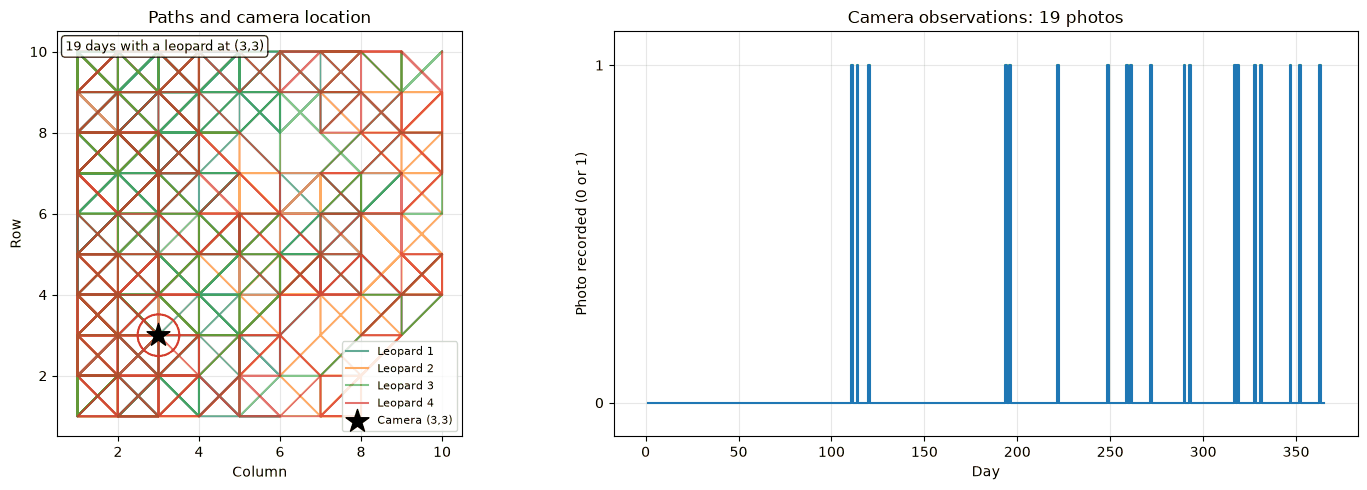

Camera count = 19; map-derived count = 19


In [14]:
def cell_id(row, col):
    # PDF/MATLAB labels start at 1; NumPy indexes start at 0.
    if not (1 <= row <= GRID_SIZE and 1 <= col <= GRID_SIZE):
        raise ValueError("Camera row and column must be between 1 and 10")
    return (row - 1) * GRID_SIZE + (col - 1)

camera_label = (3, 3)
camera_id = cell_id(*camera_label)  # Python array location (2, 2).
# Days 1..365 are observed after each daily movement; day 0 is the start.
daily_camera = np.any(paths_multi[1:] == camera_id, axis=1).astype(np.uint8)
assert daily_camera.shape == (study_days,)
assert set(np.unique(daily_camera)).issubset({0, 1})
# Count days with a leopard at (3,3) from the plotted row and column coordinates,
# independently of cell_id() and of daily_camera.
path_rows = paths_multi // GRID_SIZE + 1
path_cols = paths_multi % GRID_SIZE + 1
on_camera_cell = (path_rows == camera_label[0]) & (path_cols == camera_label[1])
map_sightings = int(on_camera_cell[1:].any(axis=1).sum())
assert daily_camera.sum() == map_sightings

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for animal in range(paths_multi.shape[1]):
    axes[0].plot(paths_multi[:, animal] % GRID_SIZE + 1,
                 paths_multi[:, animal] // GRID_SIZE + 1,
                 alpha=0.65, label=f"Leopard {animal + 1}")
axes[0].scatter(*camera_label[::-1], marker="*", s=300,
                color="black", label="Camera (3,3)", zorder=5)
axes[0].scatter(*camera_label[::-1], marker="o", s=900, facecolors="none",
                edgecolors="tab:red", linewidths=1.5, zorder=4)
axes[0].text(0.02, 0.98, f"{map_sightings} days with a leopard at (3,3)",
             transform=axes[0].transAxes, va="top", fontsize=9,
             bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
axes[0].set(xlabel="Column", ylabel="Row", xlim=(0.5, 10.5),
            ylim=(0.5, 10.5), title="Paths and camera location")
axes[0].set_aspect("equal")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
axes[1].step(np.arange(1, study_days + 1), daily_camera, where="mid")
axes[1].set(xlabel="Day", ylabel="Photo recorded (0 or 1)",
            ylim=(-0.1, 1.1), yticks=[0, 1],
            title=f"Camera observations: {daily_camera.sum()} photos")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Camera count = {daily_camera.sum()}; map-derived count = {map_sightings}")


## 3.5 Monte Carlo estimate of population
For a 365-day camera study at (3,3) with seven observed photos, estimate the most likely population N. For each fixed N, repeat the simulation 1,000 times and record the total sightings M per run. During repeated runs, store only what is needed to count sightings; keep full paths for the earlier validation plots.

Start at N = 1 and continue through N = 5; extend to larger N if the greatest estimated probability of M = 7 occurs at the boundary. Plot the sighting distributions as subplots. What is the estimated probability of exactly seven sightings for each N, and which N maximizes it? State simulation uncertainty and the final estimate.

**Python implementation:** repeated simulations, distributions, likelihood comparison, and plots.

N, estimated P(M=7 | N), Monte Carlo standard error
 1, 0.0600, 0.0075
 2, 0.0750, 0.0083
 3, 0.0570, 0.0073
 4, 0.0210, 0.0045
 5, 0.0040, 0.0020
Highest-likelihood candidate: N = 2

Comparison with N = 2 (same 1000 runs per N):
N, P ratio to best, difference, SE of difference, difference / SE
 1, 0.80, 0.0150, 0.0112, 1.3
 3, 0.76, 0.0180, 0.0111, 1.6
 4, 0.28, 0.0540, 0.0095, 5.7
 5, 0.05, 0.0710, 0.0086, 8.3
Candidates not separated from N = 2 by 2 standard errors: [1, 3]


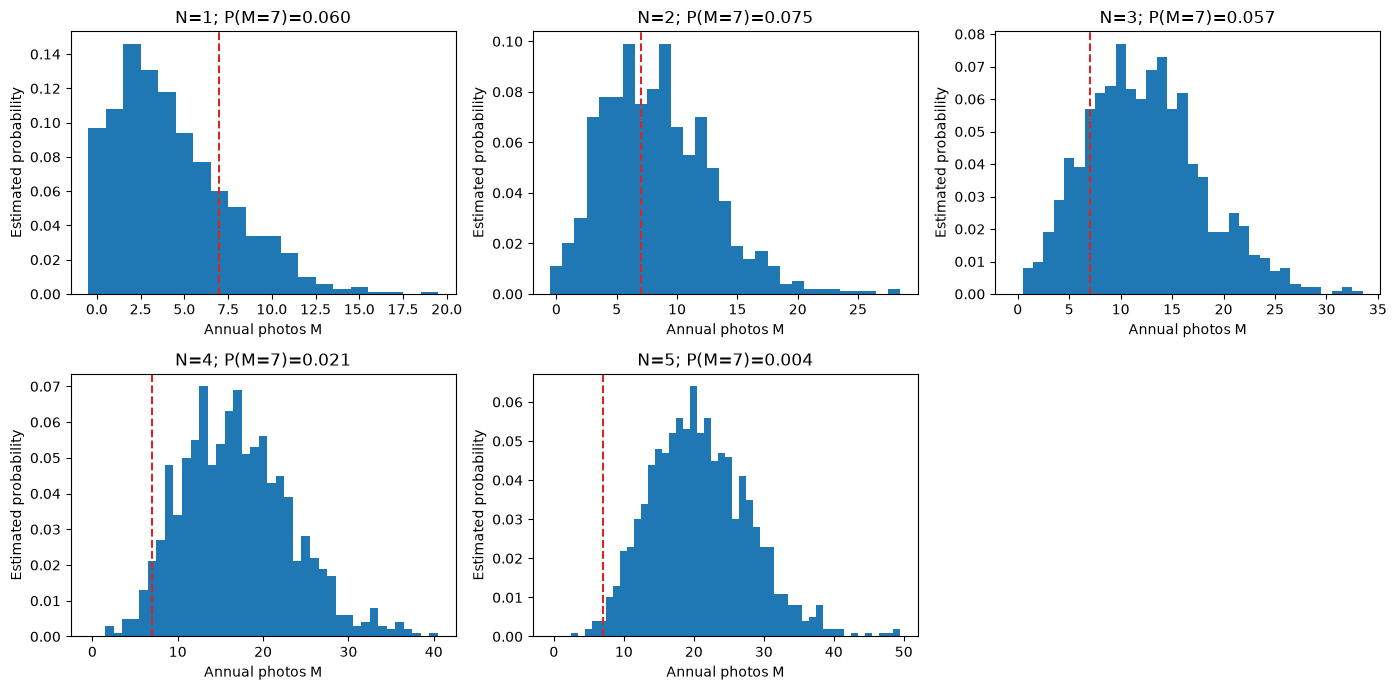

In [15]:
camera_labels = [(3, 3), (1, 1), (5, 5)]
camera_ids = np.array([cell_id(*location) for location in camera_labels])
observed_photos = 7
monte_carlo_runs = 1000
monte_carlo_rng = np.random.default_rng(46)

def simulate_camera_counts(n_leopards, runs, days, cameras, rng):
    # Only current positions and total sightings are kept, not full paths.
    # Initial cells are uniform and independent; each subsequent move is local.
    positions = rng.integers(GRID_SIZE**2, size=(runs, n_leopards))
    totals = np.zeros((runs, len(cameras)), dtype=np.int16)
    for day in range(days):
        positions = move_positions(positions, rng)
        totals += np.any(positions[:, :, None] == cameras[None, None, :],
                         axis=1)
    return totals

counts_by_n = {}
likelihood_at_seven = {}
for n_leopards in range(1, 6):
    counts_by_n[n_leopards] = simulate_camera_counts(
        n_leopards, monte_carlo_runs, study_days, camera_ids, monte_carlo_rng)
    likelihood_at_seven[n_leopards] = np.mean(
        counts_by_n[n_leopards][:, 0] == observed_photos)

# Extend beyond five only if the largest tested N remains a likelihood maximum.
while (max(counts_by_n) < 50 and
       likelihood_at_seven[max(counts_by_n)] >= max(likelihood_at_seven.values())):
    n_leopards = max(counts_by_n) + 1
    counts_by_n[n_leopards] = simulate_camera_counts(
        n_leopards, monte_carlo_runs, study_days, camera_ids, monte_carlo_rng)
    likelihood_at_seven[n_leopards] = np.mean(
        counts_by_n[n_leopards][:, 0] == observed_photos)

n_mle = max(likelihood_at_seven, key=likelihood_at_seven.get)
print("N, estimated P(M=7 | N), Monte Carlo standard error")
for n_leopards, probability in likelihood_at_seven.items():
    standard_error = np.sqrt(probability * (1 - probability) / monte_carlo_runs)
    print(f"{n_leopards:2d}, {probability:.4f}, {standard_error:.4f}")
print(f"Highest-likelihood candidate: N = {n_mle}")
if n_mle == max(counts_by_n):
    print("Maximum remains at the tested upper boundary (N=50).")

# Is the best N distinguishable from the others? Compare each candidate with the
# best using the standard error of the difference (independent runs per N).
best_p = likelihood_at_seven[n_mle]
best_se = np.sqrt(best_p * (1 - best_p) / monte_carlo_runs)
print(f"\nComparison with N = {n_mle} (same {monte_carlo_runs} runs per N):")
print("N, P ratio to best, difference, SE of difference, difference / SE")
within_two_se = []
for n_leopards, probability in likelihood_at_seven.items():
    if n_leopards == n_mle:
        continue
    se = np.sqrt(probability * (1 - probability) / monte_carlo_runs)
    se_diff = np.sqrt(best_se**2 + se**2)
    difference = best_p - probability
    z_score = difference / se_diff if se_diff > 0 else np.inf
    if z_score < 2:
        within_two_se.append(n_leopards)
    print(f"{n_leopards:2d}, {probability / best_p:.2f}, {difference:.4f}, {se_diff:.4f}, {z_score:.1f}")
print(f"Candidates not separated from N = {n_mle} by 2 standard errors: {within_two_se}")

n_plots = len(counts_by_n)
fig, axes = plt.subplots(int(np.ceil(n_plots / 3)), 3,
                         figsize=(14, 3.5 * int(np.ceil(n_plots / 3))),
                         squeeze=False)
for ax, (n_leopards, totals) in zip(axes.flat, counts_by_n.items()):
    observations = totals[:, 0]
    bins = np.arange(observations.max() + 2) - 0.5
    ax.hist(observations, bins=bins, density=True, color="tab:blue")
    ax.axvline(observed_photos, color="tab:red", linestyle="--")
    ax.set(title=f"N={n_leopards}; P(M=7)={likelihood_at_seven[n_leopards]:.3f}",
           xlabel="Annual photos M", ylabel="Estimated probability")
for ax in list(axes.flat)[n_plots:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


In [16]:
# Supplementary check (not requested by the PDF): the same estimate with 20,000 runs
# per N, so the likelihood differences can be compared with much smaller simulation error.
precision_runs = 20_000
precision_rng = np.random.default_rng(48)
precise = {}
print("N, P(M=7 | N) with 20,000 runs, standard error")
for n_leopards in range(1, 6):
    totals = simulate_camera_counts(n_leopards, precision_runs, study_days,
                                    camera_ids[:1], precision_rng)[:, 0]
    precise[n_leopards] = np.mean(totals == observed_photos)
    se = np.sqrt(precise[n_leopards] * (1 - precise[n_leopards]) / precision_runs)
    print(f"{n_leopards:2d}, {precise[n_leopards]:.4f}, {se:.4f}")
precise_best = max(precise, key=precise.get)
print(f"Highest-likelihood N with 20,000 runs: {precise_best}")
print("Likelihood relative to the best:",
      {n: round(p / precise[precise_best], 2) for n, p in precise.items()})


N, P(M=7 | N) with 20,000 runs, standard error


 1, 0.0624, 0.0017


 2, 0.0902, 0.0020


 3, 0.0551, 0.0016


 4, 0.0220, 0.0010


 5, 0.0067, 0.0006
Highest-likelihood N with 20,000 runs: 2
Likelihood relative to the best: {1: np.float64(0.69), 2: np.float64(1.0), 3: np.float64(0.61), 4: np.float64(0.24), 5: np.float64(0.07)}


In [17]:
# Supplementary sensitivity check (not requested by the PDF): does the assumed starting
# position change the population estimate? Camera at (3,3), 10,000 runs per N and start rule.
def simulate_counts_from_start(n_leopards, runs, days, camera, rng, start_rule):
    positions = start_rule(n_leopards, runs, rng)
    totals = np.zeros(runs, dtype=np.int16)
    for _ in range(days):
        positions = move_positions(positions, rng)
        totals += np.any(positions == camera, axis=1)
    return totals

start_rules = {
    "uniform over 100 cells (used above)":
        lambda n, runs, rng: rng.integers(GRID_SIZE**2, size=(runs, n)),
    "stationary (probability proportional to neighbours)":
        lambda n, runs, rng: rng.choice(GRID_SIZE**2, size=(runs, n),
                                        p=neighbor_count / neighbor_count.sum()),
    "all leopards start at the centre cell (5,5)":
        lambda n, runs, rng: np.full((runs, n), cell_id(5, 5)),
}
start_runs = 10_000
for name, rule in start_rules.items():
    start_rng = np.random.default_rng(50)
    probabilities = {}
    for n_leopards in range(1, 6):
        totals = simulate_counts_from_start(n_leopards, start_runs, study_days,
                                            cell_id(*camera_label), start_rng, rule)
        probabilities[n_leopards] = np.mean(totals == observed_photos)
    best = max(probabilities, key=probabilities.get)
    table = {n: round(float(p), 4) for n, p in probabilities.items()}
    print(f"{name}: P(M=7|N) = {table}; highest N = {best}")


uniform over 100 cells (used above): P(M=7|N) = {1: 0.0605, 2: 0.0938, 3: 0.0531, 4: 0.02, 5: 0.0061}; highest N = 2


stationary (probability proportional to neighbours): P(M=7|N) = {1: 0.0587, 2: 0.0938, 3: 0.0546, 4: 0.0202, 5: 0.0059}; highest N = 2


all leopards start at the centre cell (5,5): P(M=7|N) = {1: 0.0627, 2: 0.0911, 3: 0.0519, 4: 0.0173, 5: 0.0055}; highest N = 2


## 3.6 Choose a camera location
With N = 3 and 1,000 year-long runs per location, compare cameras at (3,3), (1,1), and (5,5). Reuse the (3,3) results if applicable. Compare the variance of each location's sighting-count distribution. Which has the smallest and largest variance? What does this mean, and where would you recommend placing the camera before the field experiment?

**Python implementation:** location comparison, distributions, variances, and plot.

Camera location, mean photos, sample variance, 95% bootstrap interval, variance / mean
(3, 3), 12.367, 31.674, [28.8, 34.4], 2.56
(1, 1), 4.541, 12.531, [11.1, 14.0], 2.76
(5, 5), 12.560, 20.547, [18.5, 22.6], 1.64


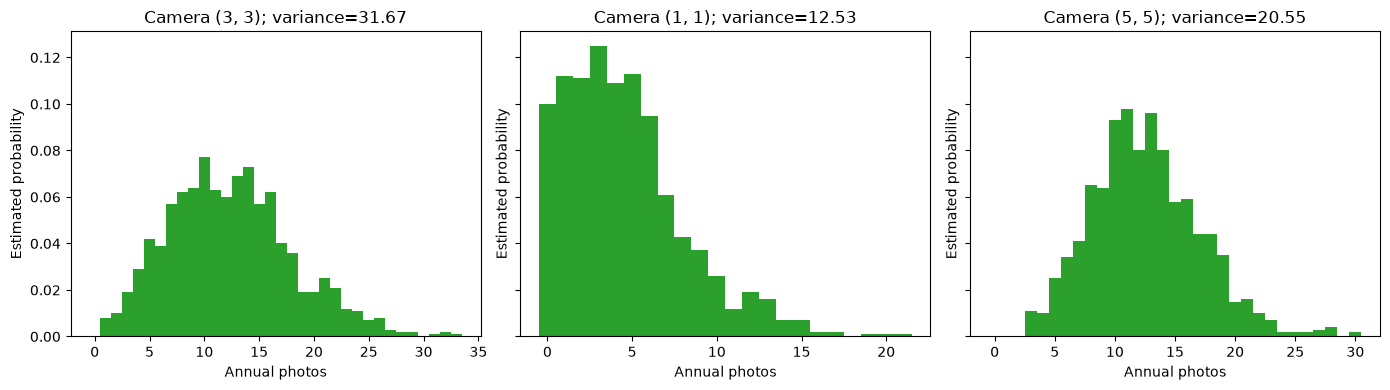

In [18]:
# The N=3 simulations above recorded all three camera cells on the same paths.
counts_n3 = counts_by_n[3]
camera_variances = np.var(counts_n3, axis=0, ddof=1)
# Bootstrap the 1,000 runs to see how much each sample variance could move.
bootstrap_rng = np.random.default_rng(49)
bootstrap_variances = np.array([
    np.var(counts_n3[bootstrap_rng.integers(0, len(counts_n3), len(counts_n3))],
           axis=0, ddof=1)
    for _ in range(2000)
])
variance_low, variance_high = np.percentile(bootstrap_variances, [2.5, 97.5], axis=0)
print("Camera location, mean photos, sample variance, 95% bootstrap interval, variance / mean")
for j, (location, totals, variance) in enumerate(
        zip(camera_labels, counts_n3.T, camera_variances)):
    print(f"{location}, {totals.mean():.3f}, {variance:.3f}, "
          f"[{variance_low[j]:.1f}, {variance_high[j]:.1f}], {variance / totals.mean():.2f}")
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, location, totals, variance in zip(
        axes, camera_labels, counts_n3.T, camera_variances):
    bins = np.arange(totals.max() + 2) - 0.5
    ax.hist(totals, bins=bins, density=True, color="tab:green")
    ax.set(title=f"Camera {location}; variance={variance:.2f}",
           xlabel="Annual photos", ylabel="Estimated probability")
plt.tight_layout()
plt.show()


## 3.7 Extra credit: precision of the population estimate
Explain why the variance of sightings M at a location differs from the variance of the population estimator N̂ based on maximum likelihood. Which criterion better measures precision of the population estimate? Describe how to estimate the variance of N̂ across camera locations.

**Response:** To be completed.

**Optional Python implementation (extra extra credit):** estimate and compare those estimator variances.

Camera (3, 3): Var(N_MLE) = 1.452; candidates 1-5; share of estimates at the largest candidate = 0.150
Camera (1, 1): Var(N_MLE) = 1.899; candidates 1-5; share of estimates at the largest candidate = 0.188
Camera (5, 5): Var(N_MLE) = 1.072; candidates 1-5; share of estimates at the largest candidate = 0.120


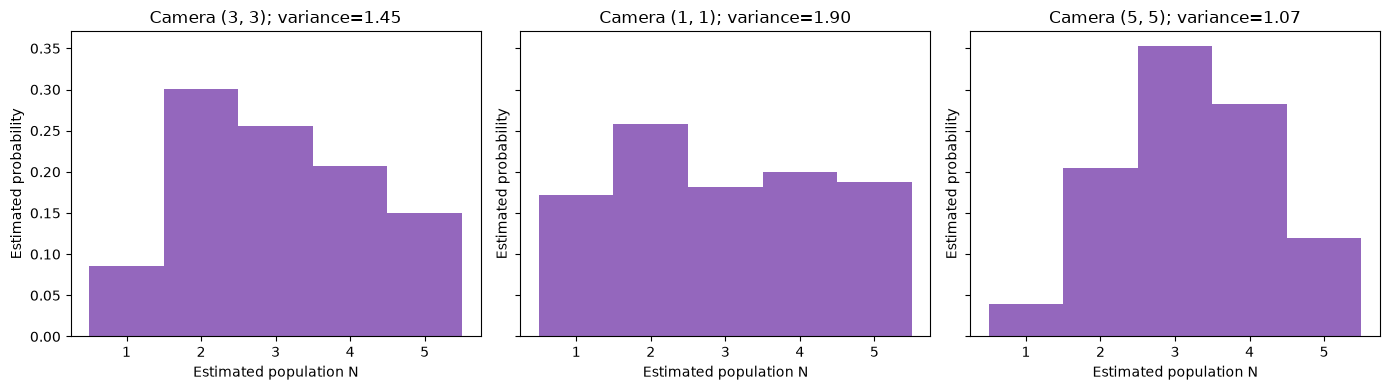

In [19]:
# Extra extra credit: independently repeat N=3 studies, then estimate N
# from the Monte Carlo likelihood table at each camera location.
evaluation_rng = np.random.default_rng(47)
evaluation_counts = simulate_camera_counts(
    3, monte_carlo_runs, study_days, camera_ids, evaluation_rng)
# Estimates are conditional on the candidate N values simulated above; a limited
# candidate range truncates the estimates and understates their spread.
candidate_n = np.array(sorted(counts_by_n))
estimated_n_by_camera = {}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for camera_index, (ax, location) in enumerate(zip(axes, camera_labels)):
    # The same small pseudocount handles unseen sighting totals; all
    # candidate populations have the same 1,000 training runs.
    likelihood_table = np.stack([
        (np.bincount(counts_by_n[n][:, camera_index],
                     minlength=study_days + 1) + 0.5)
        / (monte_carlo_runs + 0.5 * (study_days + 1))
        for n in candidate_n
    ])
    estimates = candidate_n[
        np.argmax(likelihood_table[:, evaluation_counts[:, camera_index]], axis=0)
    ]
    estimated_n_by_camera[location] = estimates
    variance = np.var(estimates, ddof=1)
    print(f"Camera {location}: Var(N_MLE) = {variance:.3f}; candidates "
          f"{candidate_n.min()}-{candidate_n.max()}; share of estimates at the largest "
          f"candidate = {np.mean(estimates == candidate_n.max()):.3f}")
    ax.hist(estimates, bins=np.arange(0.5, candidate_n.max() + 1.5),
            density=True, color="tab:purple")
    ax.set(title=f"Camera {location}; variance={variance:.2f}",
           xlabel="Estimated population N", ylabel="Estimated probability")
plt.tight_layout()
plt.show()


# Summary of results
When the analysis is complete, summarize the surface intersection, population-model behaviors, snow-leopard population estimate, and camera-location recommendation. Separate computed findings from modeling assumptions and simulation uncertainty.

**Summary:** To be completed.